# Individual-level instability of ICU risk predictions

## Notebook 1 of 3: study cohorts, harmonised predictors and data quality

**Study question.** When an ICU mortality model is rebuilt on a different sample of the same size from the same population, how much do individual patients' predicted risks, and the treatment decisions that follow from them, change? How does that instability depend on development sample size and model class, and does it carry over to patients in other hospitals?

**Data.** MIMIC-IV v2.2 (single academic centre, development) and eICU-CRD v2.0 (more than 200 US hospitals, external evaluation).

**Software.** All instability analyses use the open-source `cpmaudit` package. This notebook also uses its `TableStore` (table discovery in any folder layout) and sample-size functions.

| Notebook | Content |
|---|---|
| **1 (this notebook)** | Pre-specified design, cohort construction with flow counts, harmonised feature extraction, plausibility filtering, missingness, Table 1, case-mix comparison, eICU hospital landscape, sample-size context. Writes analysis-ready datasets for notebooks 2 and 3. |
| 2 | Development in MIMIC-IV: model classes, bootstrap instability audit at four levels, decision instability at clinical thresholds, instability against development sample size, optimism (.632+), subgroup instability. |
| 3 | External evaluation in eICU-CRD: transport of instability, hospital-level instability and heterogeneity, predictive multiplicity, sensitivity analyses (all stays with cluster bootstrap, secondary outcome), governance acceptance checks, final figures. |

**Outputs of this notebook** (folder `outputs/part1`): analysis datasets (Parquet, kept local); Table 1 and Tables S0 to S11; eight figures, each as PNG at 300 dpi and vector PDF (Figure 1 study flow, Figure 2 missingness and its information content, Figure 3 case-mix difference, Figure 4 predictor distributions, Figure 5 eICU-CRD hospital funnel plot, Figure 6 sample-size context, Figure S1 calendar period, Figure S2 recording frequency and the effect of the hourly vital-sign rule); a machine-readable analysis specification and study summary for notebooks 2 and 3; and a SHA-256 hash-chained provenance manifest.

**Run settings** (optional environment variables, set before starting Jupyter): `STUDY_MIMIC_ROOTS` and `STUDY_EICU_ROOTS` (search paths separated by `;`), `STUDY_PROJECT_DIR`, `STUDY_DUCKDB_MEMORY` (default `4GB`), `STUDY_DUCKDB_THREADS` (default 4), `STUDY_VITAL_RULE` (`first` or `mean`), `STUDY_FORCE_REBUILD=1` to ignore the extraction cache.

> **Data governance.** Files in `outputs/part1/data` and `cache` contain patient-level PhysioNet data. A `.gitignore` is written to both folders. Do not upload them to GitHub or share them.

## 1. Pre-specified design

| Element | Specification |
|---|---|
| Population | Adults (18 years or older) admitted to an ICU; first ICU stay per patient (main analysis); all eligible stays per patient (sensitivity analysis, cluster bootstrap) |
| Prediction time (landmark) | 24 hours after ICU admission; patients must still be in the ICU and alive at the landmark |
| Primary outcome | In-hospital death after the landmark |
| Secondary outcome | ICU length of stay of 7 days or more |
| Predictor window | Vital signs and GCS: from ICU admission up to (not including) the 24-h landmark. Laboratory tests: from 6 h before ICU admission up to the landmark (time of specimen collection) |
| Temporal harmonisation | eICU-CRD stores periodic vital signs every 5 minutes, whereas MIMIC-IV vital signs are charted about hourly. Summaries over unequal sampling are not comparable: more samples give more extreme minima and maxima, and averaging many samples gives smoother values. **Main rule:** one value per hour in both databases, the first valid value recorded in that hour, then minimum, maximum and mean across the 24 hourly values. **Sensitivity rule** (same extraction pass): hourly mean instead of first value. Section 9.3 quantifies how much the rule alone changes the apparent case-mix difference |
| Predictors | Age, sex; heart rate, systolic, diastolic and mean arterial pressure, respiratory rate, temperature, SpO2 (minimum, maximum and mean of the hourly values); 15 laboratory tests (minimum, maximum); GCS total where the verbal component is assessable, and GCS motor component (minimum) |
| Temperature source | Nurse-charted temperature in both databases (MIMIC-IV `chartevents` 223761/223762; eICU-CRD `nurseCharting` "Temperature (C)"). The `vitalPeriodic` temperature column is not used: it is filled only when a continuous rectal or intravascular probe is interfaced, so it covers a small, sicker subset of eICU-CRD stays and has no counterpart in the MIMIC-IV items used |
| Anion gap | Not used as a predictor. Its laboratory definition differs between sites (with or without potassium, analyser-specific chloride), it is not reported at all for a quarter of eICU-CRD stays, and it is a linear function of sodium, chloride and bicarbonate, which are included |
| GCS handling | In MIMIC-IV, verbal responses charted as not assessable because of an endotracheal or tracheostomy tube are not converted to a normal score; GCS total is left missing at those times, while the motor component (unaffected by intubation) is always used |
| Harmonisation | Identical definitions, units and plausibility limits in both databases; invasive and non-invasive pressures combined; temperatures above 50 converted from Fahrenheit |
| Exclusions | Age under 18 or unknown; ICU stay shorter than 24 h; death in hospital before the landmark; unknown hospital outcome; no valid heart-rate measurement in the first 24 h |
| Development / external | MIMIC-IV / eICU-CRD (pooled and by hospital) |

Race and ethnicity, care-unit type, hospital characteristics and calendar period are extracted for **description and subgroup analyses only**; they are not predictors.

## 2. Environment and configuration

Paths default to the local copies of both databases. Each database can be read from Parquet (faster) and/or the original CSV release. For every table the notebook uses the first location in the list where that table is found, so a partial Parquet conversion still works. Environment variables can override any path, which keeps the notebook portable for co-authors and reviewers.

In [1]:
import contextlib
import datetime as dt
import hashlib
import json
import math
import os
import platform
import sys
import time
import warnings
from pathlib import Path

import duckdb
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch

import cpmaudit
from cpmaudit import cox_snell_r2_from_c, max_cox_snell_r2, minimum_sample_size_binary
from cpmaudit.io import EICU_CRD, MIMIC_IV, TableStore

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)

ENVIRONMENT = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "processor": platform.processor(),
    "cpu_count": os.cpu_count(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "duckdb": duckdb.__version__,
    "matplotlib": matplotlib.__version__,
    "cpmaudit": cpmaudit.__version__,
}
for key, value in ENVIRONMENT.items():
    print(f"{key:>10}: {value}")

    python: 3.11.5
  platform: Windows-10-10.0.26300-SP0
 processor: Intel64 Family 6 Model 181 Stepping 0, GenuineIntel
 cpu_count: 14
     numpy: 2.4.6
    pandas: 3.1.1
    duckdb: 2.0.0
matplotlib: 3.11.2
  cpmaudit: 0.1.0


In [2]:
def _path_list(env_var, defaults):
    """Paths from an environment variable (separated by ';') or the defaults."""
    raw = os.environ.get(env_var)
    return [Path(p) for p in raw.split(";")] if raw else [Path(p) for p in defaults]


CONFIG = {
    # Search order for each database: first location containing a table wins.
    "mimic_roots": _path_list("STUDY_MIMIC_ROOTS", [r"C:\icu_parquet\mimic", r"C:\mimic-iv-2.2"]),
    "eicu_roots": _path_list(
        "STUDY_EICU_ROOTS",
        [r"C:\icu_parquet\eicu", r"C:\Users\kruta\Downloads\eicu-collaborative-research-database-2.0"],
    ),
    "project_dir": Path(os.environ.get("STUDY_PROJECT_DIR", Path.cwd())),
    # Pre-specified design parameters
    "min_age": 18,
    "landmark_hours": 24,
    "lab_lookback_hours": 6,
    "prolonged_icu_days": 7,
    "age_cap": 90,
    # Vital signs: one value per hour, either the first valid value in the hour ("first", main analysis)
    # or the hourly mean ("mean"); the other rule is kept as a sensitivity-analysis variant.
    "vital_hourly_rule": os.environ.get("STUDY_VITAL_RULE", "first"),
    # Analysis planning
    "design_sizes": [500, 1000, 2000, 4000, 8000, 16000],
    "min_hospital_stays": 100,
    "anticipated_c_grid": [0.70, 0.75, 0.80, 0.85, 0.90],
    # Compute settings (tuned for a 4-core laptop with 8-16 GB RAM)
    "duckdb_memory_limit": os.environ.get("STUDY_DUCKDB_MEMORY", "4GB"),
    "duckdb_threads": int(os.environ.get("STUDY_DUCKDB_THREADS", "4")),
    "force_rebuild": os.environ.get("STUDY_FORCE_REBUILD", "0") == "1",
    "seed": 20261120,
}

PROJECT = CONFIG["project_dir"]
OUT = PROJECT / "outputs" / "part1"
DIRS = {name: OUT / name for name in ("figures", "tables", "data", "logs")}
CACHE = PROJECT / "cache"
for folder in list(DIRS.values()) + [CACHE, CACHE / "duckdb_tmp"]:
    folder.mkdir(parents=True, exist_ok=True)
for private in (DIRS["data"], CACHE):
    (private / ".gitignore").write_text("*\n", encoding="utf-8")

np.random.seed(CONFIG["seed"])
print("Project folder:", PROJECT.resolve())
print("Outputs:       ", OUT.resolve())

Project folder: C:\Users\kruta\Downloads
Outputs:        C:\Users\kruta\Downloads\outputs\part1


### Provenance

Every saved file is hashed with SHA-256 and appended to a hash chain (each entry's chain hash covers the previous chain hash plus the file hash), so any later change to any output is detectable. Step timings are recorded with the same manifest.

In [3]:
class Provenance:
    def __init__(self, path):
        self.path = Path(path)
        self.entries, self.steps = [], []
        self.chain = "0" * 64
        self.started = dt.datetime.now(dt.timezone.utc)

    @staticmethod
    def sha256(path, block=1 << 20):
        digest = hashlib.sha256()
        with open(path, "rb") as fh:
            for chunk in iter(lambda: fh.read(block), b""):
                digest.update(chunk)
        return digest.hexdigest()

    def register(self, path, kind, description=""):
        file_hash = self.sha256(path)
        self.chain = hashlib.sha256((self.chain + file_hash).encode()).hexdigest()
        self.entries.append({
            "file": str(Path(path).relative_to(PROJECT)) if str(path).startswith(str(PROJECT)) else str(path),
            "kind": kind, "description": description, "sha256": file_hash,
            "chain_sha256": self.chain, "bytes": Path(path).stat().st_size,
        })

    @contextlib.contextmanager
    def step(self, name):
        t0 = time.perf_counter()
        print(f"\n>>> {name}")
        try:
            yield
        finally:
            seconds = round(time.perf_counter() - t0, 1)
            self.steps.append({"step": name, "seconds": seconds})
            print(f"<<< {name}: {seconds} s")

    def save(self, extra=None):
        payload = {
            "notebook": "part1_cohorts_features_quality",
            "started_utc": self.started.isoformat(timespec="seconds"),
            "finished_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
            "environment": ENVIRONMENT, "steps": self.steps, "files": self.entries,
            "final_chain_sha256": self.chain, **(extra or {}),
        }
        self.path.write_text(json.dumps(payload, indent=2, default=str), encoding="utf-8")
        return self.path


PROV = Provenance(DIRS["logs"] / "provenance_manifest.json")


def save_table(df, name, description="", index=False):
    path = DIRS["tables"] / f"{name}.csv"
    df.to_csv(path, index=index)
    PROV.register(path, "table", description)
    return path


def save_data(df, name, description=""):
    path = DIRS["data"] / f"{name}.parquet"
    df.to_parquet(path, index=False)
    PROV.register(path, "data", description)
    return path


def save_json(obj, name, description="", folder="logs"):
    path = DIRS[folder] / f"{name}.json"
    path.write_text(json.dumps(obj, indent=2, default=str), encoding="utf-8")
    PROV.register(path, "json", description)
    return path


def save_figure(fig, name, description=""):
    for ext in ("png", "pdf"):
        path = DIRS["figures"] / f"{name}.{ext}"
        fig.savefig(path, dpi=300 if ext == "png" else None, bbox_inches="tight", facecolor="white")
        PROV.register(path, f"figure-{ext}", description)
    plt.show()

### Figure style

One consistent style for all three notebooks: thin marks, recessive grid, left-aligned titles, and a fixed colour per database (blue for MIMIC-IV, orange for eICU-CRD) that never changes between figures.

In [4]:
COLORS = {"MIMIC-IV": "#2a78d6", "eICU-CRD": "#eb6834"}
NEUTRAL, INK, INK2, GRID = "#8a8984", "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 9, "axes.titlesize": 10,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelcolor": INK2,
    "axes.edgecolor": NEUTRAL, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False, "lines.linewidth": 2,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})


def panel_label(ax, letter):
    """Prefix the panel title with its letter (call after set_title)."""
    ax.set_title(f"{letter}   {ax.get_title(loc='left')}", loc="left")


def plain_log_axis(axis):
    """Plain thousands-separated tick labels on a log-scaled axis."""
    axis.set_major_locator(matplotlib.ticker.LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
    axis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    axis.set_minor_formatter(matplotlib.ticker.NullFormatter())


def smd_continuous(a, b):
    """Standardised mean difference (b minus a) with pooled standard deviation."""
    a, b = pd.Series(a).dropna(), pd.Series(b).dropna()
    if len(a) < 2 or len(b) < 2:
        return np.nan
    pooled = math.sqrt((a.var() + b.var()) / 2)
    return (b.mean() - a.mean()) / pooled if pooled > 0 else 0.0


def smd_binary(pa, pb):
    pooled = math.sqrt((pa * (1 - pa) + pb * (1 - pb)) / 2)
    return (pb - pa) / pooled if pooled > 0 else 0.0


def wilson(k, n, z=1.96):
    """Wilson score interval for a binomial proportion."""
    if n == 0:
        return np.nan, np.nan
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half

## 3. Locate the source tables

`TableStore` recognises every layout in use here: Parquet exports, module sub-folders (`hosp/`, `icu/`) and the unpacked layout where each table sits in a folder of the same name (`vitalPeriodic.csv/vitalPeriodic.csv`). CSV files are read with every column as text and converted explicitly with `TRY_CAST`, so unusual values never break a query.

In [5]:
REQUIRED = {
    "mimic": ["patients", "admissions", "icustays", "chartevents", "labevents", "d_items", "d_labitems"],
    "eicu": ["patient", "hospital", "vitalPeriodic", "vitalAperiodic", "lab", "nurseCharting"],
}
LABEL = {"mimic": "MIMIC-IV", "eicu": "eICU-CRD"}


def build_stores(db):
    stores = []
    for root in CONFIG[f"{db}_roots"]:
        if root.is_dir():
            store = TableStore(root, max_depth=4, duckdb_memory_limit=CONFIG["duckdb_memory_limit"],
                               duckdb_threads=CONFIG["duckdb_threads"])
            n = len(store.tables())
            print(f"[{LABEL[db]}] {root}: {n} tables")
            if n:
                stores.append(store)
        else:
            print(f"[{LABEL[db]}] not found, skipped: {root}")
    return stores


STORES = {db: build_stores(db) for db in REQUIRED}


def locate(db, table):
    for store in STORES[db]:
        if table in store:
            return store.path(table), store.format(table), store.root
    raise KeyError(f"{LABEL[db]} table '{table}' was not found in {CONFIG[db + '_roots']}")


def src(db, table):
    """DuckDB FROM-clause for a table, whatever its physical format."""
    path, fmt, _ = locate(db, table)
    p = str(path).replace("\\", "/").replace("'", "''")
    if fmt == "dataset":
        return f"read_parquet('{p}/**/*.parquet')"
    if fmt in (".parquet", ".pq"):
        return f"read_parquet('{p}')"
    return f"read_csv('{p}', header=true, all_varchar=true)"


rows = []
for db, tables in REQUIRED.items():
    for table in tables:
        try:
            path, fmt, root = locate(db, table)
            size = sum(f.stat().st_size for f in Path(path).rglob("*") if f.is_file()) if Path(path).is_dir() else Path(path).stat().st_size
            rows.append({"database": LABEL[db], "table": table, "format": fmt, "size_gb": round(size / 1e9, 3), "path": str(path)})
        except KeyError as exc:
            rows.append({"database": LABEL[db], "table": table, "format": "MISSING", "size_gb": np.nan, "path": str(exc)})
SOURCES = pd.DataFrame(rows)
display(SOURCES)
missing = SOURCES[SOURCES["format"] == "MISSING"]
if len(missing):
    raise FileNotFoundError("Required tables are missing:\n" + missing.to_string(index=False))

[MIMIC-IV] C:\icu_parquet\mimic: 31 tables
[MIMIC-IV] C:\mimic-iv-2.2: 154 tables
[eICU-CRD] C:\icu_parquet\eicu: 31 tables
[eICU-CRD] C:\Users\kruta\Downloads\eicu-collaborative-research-database-2.0: 31 tables


,database,table,format,size_gb,path
0,MIMIC-IV,patients,.parquet,0.001,C:\icu_parquet\mimic\hosp\patients.parquet
1,MIMIC-IV,admissions,.parquet,0.013,C:\icu_parquet\mimic\hosp\admissions.parquet
2,MIMIC-IV,icustays,.parquet,0.002,C:\icu_parquet\mimic\icu\icustays.parquet
3,MIMIC-IV,chartevents,.parquet,1.232,C:\icu_parquet\mimic\icu\chartevents.parquet
4,MIMIC-IV,labevents,.parquet,1.091,C:\icu_parquet\mimic\hosp\labevents.parquet
5,MIMIC-IV,d_items,.parquet,0.000,C:\icu_parquet\mimic\icu\d_items.parquet
6,MIMIC-IV,d_labitems,.parquet,0.000,C:\icu_parquet\mimic\hosp\d_labitems.parquet
7,eICU-CRD,patient,.parquet,0.006,C:\icu_parquet\eicu\patient.parquet
8,eICU-CRD,hospital,.parquet,0.000,C:\icu_parquet\eicu\hospital.parquet
9,eICU-CRD,vitalPeriodic,.parquet,1.389,C:\icu_parquet\eicu\vitalPeriodic.parquet


In [6]:
TMP_DIR = (CACHE / "duckdb_tmp").as_posix()
con = duckdb.connect()
con.execute(f"SET memory_limit='{CONFIG['duckdb_memory_limit']}'")
con.execute(f"SET threads={CONFIG['duckdb_threads']}")
con.execute(f"SET temp_directory='{TMP_DIR}'")
con.execute("SET preserve_insertion_order=false")


def q(sql):
    return con.execute(sql).df()


DESIGN_KEYS = ["min_age", "landmark_hours", "lab_lookback_hours", "prolonged_icu_days", "age_cap", "vital_hourly_rule"]
assert CONFIG["vital_hourly_rule"] in ("first", "mean"), "vital_hourly_rule must be 'first' or 'mean'"


def fingerprint(*objects):
    blob = json.dumps([{k: CONFIG[k] for k in DESIGN_KEYS}, *objects], sort_keys=True, default=str)
    return hashlib.sha256(blob.encode()).hexdigest()[:10]


def cached(name, builder, key):
    """Run an expensive extraction once; reuse the Parquet result on later runs."""
    path = CACHE / f"{name}_{key}.parquet"
    if path.exists() and not CONFIG["force_rebuild"]:
        df = pd.read_parquet(path)
        print(f"   cache hit: {path.name} ({len(df):,} rows)")
        return df
    t0 = time.perf_counter()
    df = builder()
    df.to_parquet(path, index=False)
    print(f"   built {path.name}: {len(df):,} rows in {time.perf_counter() - t0:.1f} s")
    return df

## 4. Harmonised feature dictionary

Each predictor has one definition, unit and plausibility range in both databases. Values outside the range are treated as recording errors and removed before aggregation (counts are reported in Table S2). The dictionary is saved as Table S1.

In [7]:
VITALS = [
    # name, label, unit, low, high, MIMIC-IV chartevents itemids, eICU (table, column)
    ("heart_rate", "Heart rate", "beats/min", 1, 300, [220045], [("vitalPeriodic", "heartrate")]),
    ("sbp", "Systolic blood pressure", "mmHg", 1, 400, [220050, 220179],
     [("vitalPeriodic", "systemicsystolic"), ("vitalAperiodic", "noninvasivesystolic")]),
    ("dbp", "Diastolic blood pressure", "mmHg", 1, 300, [220051, 220180],
     [("vitalPeriodic", "systemicdiastolic"), ("vitalAperiodic", "noninvasivediastolic")]),
    ("mbp", "Mean arterial pressure", "mmHg", 1, 300, [220052, 220181, 225312],
     [("vitalPeriodic", "systemicmean"), ("vitalAperiodic", "noninvasivemean")]),
    ("resp_rate", "Respiratory rate", "breaths/min", 1, 80, [220210, 224690], [("vitalPeriodic", "respiration")]),
    ("temperature", "Temperature", "deg C", 25, 45, [223761, 223762], [("nurseCharting", "Temperature / Temperature (C)")]),
    ("spo2", "Peripheral oxygen saturation", "%", 1, 100, [220277], [("vitalPeriodic", "sao2")]),
]
LABS = [
    # name, label, unit, low, high, MIMIC-IV labevents itemids, eICU labname values
    ("creatinine", "Creatinine", "mg/dL", 0.1, 40, [50912], ["creatinine"]),
    ("bun", "Blood urea nitrogen", "mg/dL", 1, 300, [51006], ["BUN"]),
    ("sodium", "Sodium", "mmol/L", 90, 200, [50983], ["sodium"]),
    ("potassium", "Potassium", "mmol/L", 1, 12, [50971], ["potassium"]),
    ("chloride", "Chloride", "mmol/L", 50, 180, [50902], ["chloride"]),
    ("bicarbonate", "Bicarbonate", "mmol/L", 1, 60, [50882], ["bicarbonate"]),
    ("glucose", "Glucose (laboratory)", "mg/dL", 10, 2000, [50931], ["glucose"]),
    ("hemoglobin", "Haemoglobin", "g/dL", 1, 25, [51222], ["Hgb"]),
    ("wbc", "White cell count", "x10^3/uL", 0.01, 500, [51301, 51300], ["WBC x 1000"]),
    ("platelets", "Platelet count", "x10^3/uL", 1, 2000, [51265], ["platelets x 1000"]),
    ("lactate", "Lactate", "mmol/L", 0.1, 40, [50813], ["lactate"]),
    ("bilirubin", "Total bilirubin", "mg/dL", 0.05, 80, [50885], ["total bilirubin"]),
    ("albumin", "Albumin", "g/dL", 0.5, 7, [50862], ["albumin"]),
    ("inr", "International normalised ratio", "ratio", 0.4, 20, [51237], ["PT - INR"]),
]
NEURO = [
    ("gcs_total", "GCS total (verbal assessable)", "points", 3, 15, [220739, 223900, 223901],
     [("nurseCharting", "Glasgow coma score / GCS Total"), ("nurseCharting", "Score (Glasgow Coma Scale) / Value")]),
    ("gcs_motor", "GCS motor component", "points", 1, 6, [223901],
     [("nurseCharting", "Glasgow coma score / Motor"), ("nurseCharting", "Motor Response / Value")]),
]
AGGREGATES = {"vital": ["min", "max", "mean"], "lab": ["min", "max"], "neuro": ["min"]}
GCS_ITEMS = {"eye": 220739, "verbal": 223900, "motor": 223901}

rows = []
for domain, spec in (("vital", VITALS), ("lab", LABS), ("neuro", NEURO)):
    for name, label, unit, lo, hi, mimic_src, eicu_src in spec:
        window = (f"-{CONFIG['lab_lookback_hours']} h to <{CONFIG['landmark_hours']} h" if domain == "lab"
                  else f"0 to <{CONFIG['landmark_hours']} h")
        rows.append({
            "variable": name, "label": label, "domain": domain, "unit": unit, "plausible_low": lo, "plausible_high": hi,
            "window": window,
            "aggregates": ", ".join(AGGREGATES[domain]) + (" of hourly values" if domain == "vital" else ""),
            "mimic_iv_source": ("labevents itemid " if domain == "lab" else "chartevents itemid ") + ", ".join(map(str, mimic_src)),
            "eicu_crd_source": "; ".join(f"lab.labname = '{s}'" for s in eicu_src) if domain == "lab"
            else "; ".join(f"{t}.{c}" if t != "nurseCharting" else f"nurseCharting '{c}'" for t, c in eicu_src),
        })
FEATURE_DICT = pd.DataFrame(rows)
RANGES = FEATURE_DICT.set_index("variable")[["plausible_low", "plausible_high"]]

PREDICTORS = ["age", "sex_male"] + [
    f"{r.variable}_{agg}" for r in FEATURE_DICT.itertuples() for agg in AGGREGATES[r.domain]
]
# Aggregates of one source variable are missing together: one missingness indicator per source variable.
MISSING_GROUPS = {r.variable: [f"{r.variable}_{agg}" for agg in AGGREGATES[r.domain]] for r in FEATURE_DICT.itertuples()}
BASE_VARIABLES = FEATURE_DICT["variable"].tolist()
print(f"{len(BASE_VARIABLES)} harmonised source variables -> {len(PREDICTORS)} candidate predictors")
save_table(FEATURE_DICT, "tableS1_feature_dictionary", "Harmonised predictor definitions, sources, windows and plausibility limits")
display(FEATURE_DICT[["variable", "label", "unit", "plausible_low", "plausible_high", "window", "aggregates", "mimic_iv_source", "eicu_crd_source"]])

23 harmonised source variables -> 53 candidate predictors


,variable,label,unit,plausible_low,plausible_high,window,aggregates,mimic_iv_source,eicu_crd_source
0,heart_rate,Heart rate,beats/min,1.00,300,0 to <24 h,"min, max, mean of hourly values",chartevents itemid 220045,vitalPeriodic.heartrate
1,sbp,Systolic blood pressure,mmHg,1.00,400,0 to <24 h,"min, max, mean of hourly values","chartevents itemid 220050, 220179",vitalPeriodic.systemicsystolic; vitalAperiodic.noninvasivesystolic
2,dbp,Diastolic blood pressure,mmHg,1.00,300,0 to <24 h,"min, max, mean of hourly values","chartevents itemid 220051, 220180",vitalPeriodic.systemicdiastolic; vitalAperiodic.noninvasivediastolic
3,mbp,Mean arterial pressure,mmHg,1.00,300,0 to <24 h,"min, max, mean of hourly values","chartevents itemid 220052, 220181, 225312",vitalPeriodic.systemicmean; vitalAperiodic.noninvasivemean
4,resp_rate,Respiratory rate,breaths/min,1.00,80,0 to <24 h,"min, max, mean of hourly values","chartevents itemid 220210, 224690",vitalPeriodic.respiration
5,temperature,Temperature,deg C,25.00,45,0 to <24 h,"min, max, mean of hourly values","chartevents itemid 223761, 223762",nurseCharting 'Temperature / Temperature (C)'
6,spo2,Peripheral oxygen saturation,%,1.00,100,0 to <24 h,"min, max, mean of hourly values",chartevents itemid 220277,vitalPeriodic.sao2
7,creatinine,Creatinine,mg/dL,0.10,40,-6 h to <24 h,"min, max",labevents itemid 50912,lab.labname = 'creatinine'
8,bun,Blood urea nitrogen,mg/dL,1.00,300,-6 h to <24 h,"min, max",labevents itemid 51006,lab.labname = 'BUN'
9,sodium,Sodium,mmol/L,90.00,200,-6 h to <24 h,"min, max",labevents itemid 50983,lab.labname = 'sodium'


### Verify item definitions against the local dictionaries

Every MIMIC-IV item identifier is looked up in `d_items` / `d_labitems` and every eICU laboratory name is counted in `lab`. A missing or unexpected label stops the notebook rather than silently producing an empty predictor.

In [8]:
EXPECTED_WORDS = {
    "heart_rate": ["heart rate"], "sbp": ["systolic"], "dbp": ["diastolic"], "mbp": ["mean"],
    "resp_rate": ["respiratory rate"], "temperature": ["temperature"], "spo2": ["o2 saturation", "spo2"],
    "gcs_total": ["gcs"], "gcs_motor": ["gcs"],
    "creatinine": ["creatinine"], "bun": ["urea"], "sodium": ["sodium"], "potassium": ["potassium"],
    "chloride": ["chloride"], "bicarbonate": ["bicarbonate"], "glucose": ["glucose"], "hemoglobin": ["hemoglobin"],
    "wbc": ["white", "wbc"], "platelets": ["platelet"], "lactate": ["lactate"], "bilirubin": ["bilirubin"],
    "albumin": ["albumin"], "anion_gap": ["anion"], "inr": ["inr"],
}
item_rows = [(i, name, "d_items") for name, *_, ids, _e in VITALS + NEURO for i in ids]
item_rows += [(i, name, "d_labitems") for name, *_, ids, _e in LABS for i in ids]
ITEMS = pd.DataFrame(item_rows, columns=["itemid", "variable", "dictionary"]).drop_duplicates(["itemid", "variable"])

labels = pd.concat([
    q(f"SELECT TRY_CAST(itemid AS BIGINT) AS itemid, CAST(label AS VARCHAR) AS label FROM {src('mimic', 'd_items')}"),
    q(f"SELECT TRY_CAST(itemid AS BIGINT) AS itemid, CAST(label AS VARCHAR) AS label FROM {src('mimic', 'd_labitems')}"),
])
check = ITEMS.merge(labels.drop_duplicates("itemid"), on="itemid", how="left")
check["label_matches"] = [
    isinstance(lbl, str) and any(w in lbl.lower() for w in EXPECTED_WORDS[var])
    for var, lbl in zip(check["variable"], check["label"])
]
display(check)
problems = check[check["label"].isna() | ~check["label_matches"]]
if len(problems):
    raise ValueError("MIMIC-IV item identifiers not found or with unexpected labels:\n" + problems.to_string(index=False))

lab_names = [n for *_, names in LABS for n in names]
name_list = ", ".join("'" + n.replace("'", "''") + "'" for n in lab_names)
eicu_lab_counts = q(f"""
    SELECT CAST(labname AS VARCHAR) AS labname, count(*) AS n_rows
    FROM {src('eicu', 'lab')} WHERE CAST(labname AS VARCHAR) IN ({name_list}) GROUP BY 1 ORDER BY 2 DESC
""")
display(eicu_lab_counts)
absent = sorted(set(lab_names) - set(eicu_lab_counts["labname"]))
if absent:
    raise ValueError(f"eICU lab names with no rows: {absent}")
print("All item definitions verified.")

,itemid,variable,dictionary,label,label_matches
0,220045,heart_rate,d_items,Heart Rate,True
1,220050,sbp,d_items,Arterial Blood Pressure systolic,True
2,220179,sbp,d_items,Non Invasive Blood Pressure systolic,True
3,220051,dbp,d_items,Arterial Blood Pressure diastolic,True
4,220180,dbp,d_items,Non Invasive Blood Pressure diastolic,True
5,220052,mbp,d_items,Arterial Blood Pressure mean,True
6,220181,mbp,d_items,Non Invasive Blood Pressure mean,True
7,225312,mbp,d_items,ART BP Mean,True
8,220210,resp_rate,d_items,Respiratory Rate,True
9,224690,resp_rate,d_items,Respiratory Rate (Total),True


,labname,n_rows
0,potassium,1493261
1,sodium,1393205
2,glucose,1319496
3,Hgb,1298708
4,chloride,1283839
5,creatinine,1277760
6,BUN,1270484
7,bicarbonate,1199866
8,platelets x 1000,1149488
9,WBC x 1000,1134952


All item definitions verified.


## 5. Cohort construction: MIMIC-IV

Age at ICU admission is `anchor_age + (year of ICU admission - anchor_year)`, capped at 90 to match eICU-CRD. Exclusions are applied in a fixed order so that the flow diagram is reproducible. Eligibility for the all-stays sensitivity cohort is recorded at the same time.

In [9]:
def apply_flow(df, steps, start_label):
    """Apply exclusion steps in order; return the kept mask and a flow table."""
    keep = pd.Series(True, index=df.index)
    flow = [{"step": start_label, "exclusion": "", "excluded": 0, "remaining": len(df)}]
    for label, reason, mask in steps:
        mask = mask.fillna(False).astype(bool)
        new_keep = keep & mask
        flow.append({"step": label, "exclusion": reason, "excluded": int((keep & ~mask).sum()), "remaining": int(new_keep.sum())})
        keep = new_keep
    return keep, pd.DataFrame(flow)


def race_group_mimic(value):
    v = str(value).upper()
    if "WHITE" in v or "PORTUGUESE" in v:
        return "White"
    if "BLACK" in v:
        return "Black"
    if "HISPANIC" in v or "SOUTH AMERICAN" in v:
        return "Hispanic"
    if "ASIAN" in v:
        return "Asian"
    return "Other or unknown"


def care_unit_group(value):
    v = str(value).lower()
    if "neuro" in v:
        return "Neurological"
    if any(k in v for k in ("cardiac", "coronary", "ccu", "cvicu", "ctic", "csicu")):
        return "Cardiac / cardiac surgery"
    if ("micu/sicu" in v) or ("med-surg" in v) or ("medical/surgical" in v):
        return "Mixed medical-surgical"
    if "surg" in v or "sicu" in v or "trauma" in v:
        return "Surgical / trauma"
    if "medical" in v or "micu" in v:
        return "Medical"
    return "Other"


H = CONFIG["landmark_hours"]
with PROV.step("MIMIC-IV cohort"):
    m = q(f"""
        SELECT TRY_CAST(i.subject_id AS BIGINT) AS subject_id, TRY_CAST(i.hadm_id AS BIGINT) AS hadm_id,
               TRY_CAST(i.stay_id AS BIGINT) AS stay_id, CAST(i.first_careunit AS VARCHAR) AS first_careunit,
               TRY_CAST(i.intime AS TIMESTAMP) AS intime, TRY_CAST(i.outtime AS TIMESTAMP) AS outtime,
               CAST(p.gender AS VARCHAR) AS gender, TRY_CAST(p.anchor_age AS INTEGER) AS anchor_age,
               TRY_CAST(p.anchor_year AS INTEGER) AS anchor_year, CAST(p.anchor_year_group AS VARCHAR) AS anchor_year_group,
               TRY_CAST(a.dischtime AS TIMESTAMP) AS dischtime, TRY_CAST(a.deathtime AS TIMESTAMP) AS deathtime,
               TRY_CAST(a.hospital_expire_flag AS INTEGER) AS hospital_expire_flag,
               CAST(a.race AS VARCHAR) AS race, CAST(a.admission_type AS VARCHAR) AS admission_type
        FROM {src('mimic', 'icustays')} i
        JOIN {src('mimic', 'patients')} p ON TRY_CAST(p.subject_id AS BIGINT) = TRY_CAST(i.subject_id AS BIGINT)
        LEFT JOIN {src('mimic', 'admissions')} a ON TRY_CAST(a.hadm_id AS BIGINT) = TRY_CAST(i.hadm_id AS BIGINT)
    """)
    m["age"] = (m["anchor_age"] + (m["intime"].dt.year - m["anchor_year"])).clip(upper=CONFIG["age_cap"])
    m["icu_los_hours"] = (m["outtime"] - m["intime"]).dt.total_seconds() / 3600
    m["landmark_time"] = m["intime"] + pd.Timedelta(hours=H)
    death_time = m["deathtime"].where(m["deathtime"].notna(), m["dischtime"].where(m["hospital_expire_flag"] == 1))
    m["is_first_stay"] = m.groupby("subject_id")["intime"].rank(method="first") == 1

    adult = m["age"] >= CONFIG["min_age"]
    long_enough = m["icu_los_hours"] >= H
    alive_at_landmark = ~(death_time.notna() & (death_time <= m["landmark_time"]))
    outcome_known = m["hospital_expire_flag"].isin([0, 1])

    m_keep_main, m_flow = apply_flow(m, [
        ("Aged 18 years or older", "Age under 18 or unknown", adult),
        ("First ICU stay of the patient", "Subsequent ICU stays", m["is_first_stay"]),
        (f"ICU stay of {H} h or longer", f"ICU stay shorter than {H} h", long_enough),
        ("Alive at the 24-h landmark", "Died in hospital before the landmark", alive_at_landmark),
        ("Hospital outcome known", "Unknown hospital outcome", outcome_known),
    ], "All ICU stays")
    m["eligible_all_stays"] = adult & long_enough & alive_at_landmark & outcome_known
    m["eligible_main"] = m_keep_main
    m["outcome_hospital_mortality"] = m["hospital_expire_flag"].astype("Int64")
    m["outcome_icu_los_7d"] = (m["icu_los_hours"] >= 24 * CONFIG["prolonged_icu_days"]).astype(int)
    m["race_group"] = m["race"].map(race_group_mimic)
    m["care_unit_group"] = m["first_careunit"].map(care_unit_group)
    m["sex"] = m["gender"].str.upper().str[0].where(m["gender"].str.upper().str[0].isin(["F", "M"]))

display(m_flow)
print(f"Eligible stays for extraction (all-stays cohort): {int(m['eligible_all_stays'].sum()):,}")


>>> MIMIC-IV cohort
<<< MIMIC-IV cohort: 0.6 s


,step,exclusion,excluded,remaining
0,All ICU stays,,0,73181
1,Aged 18 years or older,Age under 18 or unknown,0,73181
2,First ICU stay of the patient,Subsequent ICU stays,22261,50920
3,ICU stay of 24 h or longer,ICU stay shorter than 24 h,10753,40167
4,Alive at the 24-h landmark,Died in hospital before the landmark,135,40032
5,Hospital outcome known,Unknown hospital outcome,0,40032


Eligible stays for extraction (all-stays cohort): 57,534


## 6. Cohort construction: eICU-CRD

Ages recorded as "> 89" are set to 90. One stay per patient is selected deterministically: earliest hospital discharge year, then lowest health-system stay identifier, then first unit visit. eICU event times are offsets in minutes from unit admission.

In [10]:
def race_group_eicu(value):
    v = str(value).lower()
    return {"caucasian": "White", "african american": "Black", "hispanic": "Hispanic", "asian": "Asian"}.get(v, "Other or unknown")


LM = 60 * H
with PROV.step("eICU-CRD cohort"):
    e = q(f"""
        SELECT TRY_CAST(p.patientunitstayid AS BIGINT) AS stay_id,
               TRY_CAST(p.patienthealthsystemstayid AS BIGINT) AS encounter_id,
               CAST(p.uniquepid AS VARCHAR) AS uniquepid, TRY_CAST(p.hospitalid AS BIGINT) AS hospitalid,
               CAST(p.gender AS VARCHAR) AS gender, CAST(p.age AS VARCHAR) AS age_raw,
               CAST(p.ethnicity AS VARCHAR) AS ethnicity, CAST(p.unittype AS VARCHAR) AS unittype,
               TRY_CAST(p.unitvisitnumber AS INTEGER) AS unitvisitnumber,
               TRY_CAST(p.hospitaldischargeyear AS INTEGER) AS discharge_year,
               TRY_CAST(p.hospitaldischargeoffset AS BIGINT) AS hospitaldischargeoffset,
               CAST(p.hospitaldischargestatus AS VARCHAR) AS hospitaldischargestatus,
               TRY_CAST(p.unitdischargeoffset AS BIGINT) AS unitdischargeoffset,
               CAST(h.region AS VARCHAR) AS hospital_region, CAST(h.teachingstatus AS VARCHAR) AS hospital_teaching,
               CAST(h.numbedscategory AS VARCHAR) AS hospital_beds
        FROM {src('eicu', 'patient')} p
        LEFT JOIN {src('eicu', 'hospital')} h ON TRY_CAST(h.hospitalid AS BIGINT) = TRY_CAST(p.hospitalid AS BIGINT)
    """)
    age_text = e["age_raw"].fillna("").str.strip().str.replace("> 89", "90", regex=False)
    e["age"] = pd.to_numeric(age_text, errors="coerce").clip(upper=CONFIG["age_cap"])
    e["icu_los_hours"] = e["unitdischargeoffset"] / 60
    order = e.sort_values(["uniquepid", "discharge_year", "encounter_id", "unitvisitnumber"]).index
    e["is_first_stay"] = False
    e.loc[order, "is_first_stay"] = ~e.loc[order, "uniquepid"].duplicated()

    status = e["hospitaldischargestatus"].fillna("").str.strip().str.lower()
    adult = e["age"] >= CONFIG["min_age"]
    long_enough = e["unitdischargeoffset"] >= LM
    alive_at_landmark = ~((status == "expired") & (e["hospitaldischargeoffset"] <= LM))
    outcome_known = status.isin(["alive", "expired"])

    e_keep_main, e_flow = apply_flow(e, [
        ("Aged 18 years or older", "Age under 18 or unknown", adult),
        ("First ICU stay of the patient", "Subsequent ICU stays", e["is_first_stay"]),
        (f"ICU stay of {H} h or longer", f"ICU stay shorter than {H} h", long_enough),
        ("Alive at the 24-h landmark", "Died in hospital before the landmark", alive_at_landmark),
        ("Hospital outcome known", "Unknown hospital outcome", outcome_known),
    ], "All ICU stays")
    e["eligible_all_stays"] = adult & long_enough & alive_at_landmark & outcome_known
    e["eligible_main"] = e_keep_main
    e["outcome_hospital_mortality"] = (status == "expired").astype(int)
    e["outcome_icu_los_7d"] = (e["icu_los_hours"] >= 24 * CONFIG["prolonged_icu_days"]).astype(int)
    e["race_group"] = e["ethnicity"].map(race_group_eicu)
    e["care_unit_group"] = e["unittype"].map(care_unit_group)
    g = e["gender"].fillna("").str.strip().str.lower()
    e["sex"] = np.where(g == "female", "F", np.where(g == "male", "M", None))

display(e_flow)
print(f"Eligible stays for extraction (all-stays cohort): {int(e['eligible_all_stays'].sum()):,}")
print(f"Hospitals contributing eligible stays: {e.loc[e['eligible_all_stays'], 'hospitalid'].nunique()}")


>>> eICU-CRD cohort
<<< eICU-CRD cohort: 2.2 s


,step,exclusion,excluded,remaining
0,All ICU stays,,0,200859
1,Aged 18 years or older,Age under 18 or unknown,625,200234
2,First ICU stay of the patient,Subsequent ICU stays,61382,138852
3,ICU stay of 24 h or longer,ICU stay shorter than 24 h,42379,96473
4,Alive at the 24-h landmark,Died in hospital before the landmark,23,96450
5,Hospital outcome known,Unknown hospital outcome,894,95556


Eligible stays for extraction (all-stays cohort): 131,386
Hospitals contributing eligible stays: 207


### Integrity check against the published release counts

Row counts of the local copies are compared with the counts published for each release. A mismatch does not stop the notebook but means the local copy is incomplete or a different version, which must be resolved before the results are reported.

In [11]:
REFERENCE_COUNTS = pd.DataFrame([
    ("MIMIC-IV v2.2", "ICU stays (icustays rows)", 73_181, len(m)),
    ("MIMIC-IV v2.2", "Patients with an ICU stay", 50_920, m["subject_id"].nunique()),
    ("eICU-CRD v2.0", "ICU stays (patient rows)", 200_859, len(e)),
    ("eICU-CRD v2.0", "Unique patients", 139_367, e["uniquepid"].nunique()),
    ("eICU-CRD v2.0", "Hospitals", 208, e["hospitalid"].nunique()),
], columns=["release", "quantity", "published", "local"])
REFERENCE_COUNTS["matches"] = REFERENCE_COUNTS["published"] == REFERENCE_COUNTS["local"]
display(REFERENCE_COUNTS)
if not REFERENCE_COUNTS["matches"].all():
    warnings.warn("Local row counts differ from the published release counts; check the database copies before reporting.")
save_table(REFERENCE_COUNTS, "tableS0_release_integrity", "Local row counts compared with published release counts")

,release,quantity,published,local,matches
0,MIMIC-IV v2.2,ICU stays (icustays rows),73181,73181,True
1,MIMIC-IV v2.2,Patients with an ICU stay,50920,50920,True
2,eICU-CRD v2.0,ICU stays (patient rows),200859,200859,True
3,eICU-CRD v2.0,Unique patients,139367,139367,True
4,eICU-CRD v2.0,Hospitals,208,208,True


WindowsPath('C:/Users/kruta/Downloads/outputs/part1/tables/tableS0_release_integrity.csv')

## 7. Feature extraction

All extraction runs inside DuckDB, reading only the needed columns and rows and aggregating per stay, so multi-gigabyte event tables never enter Python memory. Each large table is scanned **once**. Results are cached as Parquet, keyed by the design parameters and the cohort, so re-running the notebook skips finished steps.

**Run time.** On a 4-core laptop the first run on the CSV releases takes roughly 30 to 90 minutes, dominated by `chartevents` (MIMIC-IV) and `vitalPeriodic` and `nurseCharting` (eICU-CRD). Parquet sources and later runs are much faster.

Extraction covers every stay eligible for the all-stays cohort, so the sensitivity analysis in notebook 3 needs no second extraction.

**eICU-CRD nurseCharting** is scanned once for both temperature and GCS (the GCS total and motor component are charted under two different labels depending on the hospital's documentation form; both are used).

**Aggregation rules.** Vital signs: plausibility filter; in each hour from admission to the landmark, the first valid value (main rule) and the mean of valid values (sensitivity rule), both from the same pass; then minimum, maximum and mean across hours. Where a variable has two sources (invasive and non-invasive blood pressure), the earliest valid value in the hour is used, ties broken deterministically. Laboratory tests: plausibility filter, then minimum and maximum in the window. GCS: minimum over assessments.

In [12]:
m_ext = m.loc[m["eligible_all_stays"], ["stay_id", "subject_id", "intime"]].copy()
e_ext = e.loc[e["eligible_all_stays"], ["stay_id"]].copy()
con.register("m_ext_df", m_ext)
con.register("e_ext_df", e_ext)
LB = CONFIG["lab_lookback_hours"]
con.execute(f"""
    CREATE OR REPLACE TEMP TABLE cohort_m AS
    SELECT CAST(stay_id AS BIGINT) AS stay_id, CAST(subject_id AS BIGINT) AS subject_id,
           CAST(intime AS TIMESTAMP) AS intime,
           CAST(intime AS TIMESTAMP) + INTERVAL {H} HOUR AS t_end,
           CAST(intime AS TIMESTAMP) - INTERVAL {LB} HOUR AS t_lab_start
    FROM m_ext_df
""")
con.execute("CREATE OR REPLACE TEMP TABLE cohort_e AS SELECT CAST(stay_id AS BIGINT) AS stay_id FROM e_ext_df")

ranges_df = RANGES.reset_index().rename(columns={"variable": "feature", "plausible_low": "lo", "plausible_high": "hi"})
con.register("ranges", ranges_df)
chart_map = pd.DataFrame([(i, name) for name, *_, ids, _e in VITALS for i in ids], columns=["itemid", "feature"])
lab_map_m = pd.DataFrame([(i, name) for name, *_, ids, _e in LABS for i in ids], columns=["itemid", "feature"])
lab_map_e = pd.DataFrame([(n, name) for name, *_, _i, names in LABS for n in names], columns=["labname", "feature"])
for name, frame in (("chart_map", chart_map), ("lab_map_m", lab_map_m), ("lab_map_e", lab_map_e)):
    con.register(name, frame)


def to_celsius(expr):
    """Temperatures above 50 are Fahrenheit recordings."""
    return f"(CASE WHEN {expr} > 50 THEN ({expr} - 32) * 5.0 / 9.0 ELSE {expr} END)"


# Second stage for vital signs. Input rows: (stay_id, feature, hr, n_raw, n_valid, s_valid, x_first, t_first),
# possibly several rows per hour (one per source table). t is time since ICU admission (seconds in MIMIC-IV,
# minutes in eICU-CRD). Ordering key t * 10000 + x: earliest value first, ties broken by the smaller value
# (valid values lie well below 10000), so the result is deterministic.
VITAL_FINAL_SQL = """
    SELECT stay_id, feature, sum(n_raw) AS n_raw, sum(n_valid) AS n_valid, count(x_mean) AS n_hours,
           min(x_first) AS first_min, max(x_first) AS first_max, avg(x_first) AS first_mean,
           min(x_mean) AS hmean_min, max(x_mean) AS hmean_max, avg(x_mean) AS hmean_mean
    FROM (
        SELECT stay_id, feature, hr, sum(n_raw) AS n_raw, sum(n_valid) AS n_valid,
               sum(s_valid) / NULLIF(sum(n_valid), 0) AS x_mean,
               arg_min(x_first, t_first * 10000 + x_first) FILTER (WHERE x_first IS NOT NULL) AS x_first
        FROM {hourly}
        WHERE hr BETWEEN 0 AND {last_hour}
        GROUP BY stay_id, feature, hr
    )
    GROUP BY stay_id, feature
"""
RULE_MAIN, RULE_ALT = ("first", "hmean") if CONFIG["vital_hourly_rule"] == "first" else ("hmean", "first")
ALT_SUFFIX = "_hourly_mean" if RULE_ALT == "hmean" else "_hourly_first"


def finish_vitals(df):
    """Name the main-rule summaries v_* and the alternative-rule summaries alt_*."""
    names = {f"{RULE_MAIN}_{s}": f"v_{s}" for s in ("min", "max", "mean")}
    names.update({f"{RULE_ALT}_{s}": f"alt_{s}" for s in ("min", "max", "mean")})
    return df.rename(columns=names)

# Laboratory tests: input rows are (stay_id, feature, x).
LAB_SQL = """
    SELECT stay_id, feature, count(*) AS n_raw,
           count(*) FILTER (WHERE x BETWEEN r.lo AND r.hi) AS n_valid,
           min(x) FILTER (WHERE x BETWEEN r.lo AND r.hi) AS v_min,
           max(x) FILTER (WHERE x BETWEEN r.lo AND r.hi) AS v_max,
           avg(x) FILTER (WHERE x BETWEEN r.lo AND r.hi) AS v_mean
    FROM {source} AS src JOIN ranges r USING (feature)
    WHERE x IS NOT NULL
    GROUP BY stay_id, feature
"""
KEY_M = fingerprint(int(m_ext["stay_id"].sum()), len(m_ext), chart_map.values.tolist(), lab_map_m.values.tolist(), "v4")
KEY_E = fingerprint(int(e_ext["stay_id"].sum()), len(e_ext), lab_map_e.values.tolist(), "v4")
print(f"Stays to extract: MIMIC-IV {len(m_ext):,}; eICU-CRD {len(e_ext):,}. Cache keys: {KEY_M}, {KEY_E}")

Stays to extract: MIMIC-IV 57,534; eICU-CRD 131,386. Cache keys: 3afda2e75d, 5962939ce2


In [13]:
chart_ids = sorted(set(chart_map["itemid"]) | set(GCS_ITEMS.values()))
LAST_HOUR = H - 1


def build_mimic_chart():
    # One scan of chartevents: keep the needed items inside the 24-h window.
    con.execute(f"""
        CREATE OR REPLACE TEMP TABLE m_chart AS
        WITH ce AS (
            SELECT TRY_CAST(stay_id AS BIGINT) AS stay_id, TRY_CAST(itemid AS BIGINT) AS itemid,
                   TRY_CAST(charttime AS TIMESTAMP) AS charttime, TRY_CAST(valuenum AS DOUBLE) AS valuenum,
                   CAST(value AS VARCHAR) AS value
            FROM {src('mimic', 'chartevents')}
            WHERE TRY_CAST(itemid AS BIGINT) IN ({", ".join(map(str, chart_ids))})
        )
        SELECT ce.stay_id, ce.itemid, ce.charttime, ce.valuenum,
               CASE WHEN ce.itemid = {GCS_ITEMS['verbal']} THEN ce.value END AS value,
               epoch(ce.charttime) - epoch(c.intime) AS t_rel,
               CAST(floor((epoch(ce.charttime) - epoch(c.intime)) / 3600.0) AS INTEGER) AS hr
        FROM ce JOIN cohort_m c USING (stay_id)
        WHERE ce.charttime >= c.intime AND ce.charttime < c.t_end
    """)
    hourly = f"""(
        SELECT stay_id, feature, hr, count(*) AS n_raw,
               count(*) FILTER (WHERE x BETWEEN r.lo AND r.hi) AS n_valid,
               sum(x) FILTER (WHERE x BETWEEN r.lo AND r.hi) AS s_valid,
               arg_min(x, t * 10000 + x) FILTER (WHERE x BETWEEN r.lo AND r.hi) AS x_first,
               min(t) FILTER (WHERE x BETWEEN r.lo AND r.hi) AS t_first
        FROM (
            SELECT ch.stay_id, mp.feature, ch.hr, ch.t_rel AS t,
                   CASE WHEN mp.feature = 'temperature' THEN {to_celsius('ch.valuenum')} ELSE ch.valuenum END AS x
            FROM m_chart ch JOIN chart_map mp USING (itemid)
            WHERE ch.valuenum IS NOT NULL
        ) AS v JOIN ranges r USING (feature)
        GROUP BY stay_id, feature, hr
    )"""
    vit = finish_vitals(q(VITAL_FINAL_SQL.format(hourly=hourly, last_hour=LAST_HOUR)))
    gcs = q(f"""
        WITH g AS (
            SELECT stay_id, charttime,
                   max(CASE WHEN itemid = {GCS_ITEMS['eye']} THEN valuenum END) AS eye,
                   max(CASE WHEN itemid = {GCS_ITEMS['motor']} THEN valuenum END) AS motor,
                   max(CASE WHEN itemid = {GCS_ITEMS['verbal']} THEN valuenum END) AS verbal,
                   max(CASE WHEN itemid = {GCS_ITEMS['verbal']}
                            AND (value ILIKE '%ETT%' OR value ILIKE '%trach%' OR value ILIKE '%intubat%') THEN 1 ELSE 0 END) AS verbal_na
            FROM m_chart WHERE itemid IN ({GCS_ITEMS['eye']}, {GCS_ITEMS['motor']}, {GCS_ITEMS['verbal']})
            GROUP BY stay_id, charttime
        )
        SELECT stay_id, 'gcs_motor' AS feature, count(motor) AS n_raw,
               count(motor) FILTER (WHERE motor BETWEEN 1 AND 6) AS n_valid,
               min(motor) FILTER (WHERE motor BETWEEN 1 AND 6) AS v_min,
               NULL::DOUBLE AS v_max, NULL::DOUBLE AS v_mean,
               NULL::BIGINT AS gcs_sets, NULL::BIGINT AS gcs_sets_verbal_na
        FROM g GROUP BY stay_id
        UNION ALL
        SELECT stay_id, 'gcs_total' AS feature,
               count(*) FILTER (WHERE verbal_na = 0 AND eye IS NOT NULL AND motor IS NOT NULL AND verbal IS NOT NULL) AS n_raw,
               count(*) FILTER (WHERE verbal_na = 0 AND eye BETWEEN 1 AND 4 AND motor BETWEEN 1 AND 6 AND verbal BETWEEN 1 AND 5) AS n_valid,
               min(eye + motor + verbal) FILTER (WHERE verbal_na = 0 AND eye BETWEEN 1 AND 4
                                                 AND motor BETWEEN 1 AND 6 AND verbal BETWEEN 1 AND 5) AS v_min,
               NULL::DOUBLE AS v_max, NULL::DOUBLE AS v_mean,
               count(*) FILTER (WHERE verbal IS NOT NULL) AS gcs_sets, sum(verbal_na) AS gcs_sets_verbal_na
        FROM g GROUP BY stay_id
    """)
    con.execute("DROP TABLE IF EXISTS m_chart")
    return pd.concat([vit, gcs], ignore_index=True)


def build_mimic_labs():
    return q(LAB_SQL.format(source=f"""(
        SELECT c.stay_id, mp.feature, le.x
        FROM (
            SELECT TRY_CAST(subject_id AS BIGINT) AS subject_id, TRY_CAST(itemid AS BIGINT) AS itemid,
                   TRY_CAST(charttime AS TIMESTAMP) AS charttime, TRY_CAST(valuenum AS DOUBLE) AS x
            FROM {src('mimic', 'labevents')}
            WHERE TRY_CAST(itemid AS BIGINT) IN ({", ".join(map(str, lab_map_m["itemid"]))})
        ) le
        JOIN lab_map_m mp USING (itemid)
        JOIN cohort_m c ON c.subject_id = le.subject_id
        WHERE le.charttime >= c.t_lab_start AND le.charttime < c.t_end
    )"""))


with PROV.step("MIMIC-IV chartevents (vital signs, GCS)"):
    mimic_chart_long = cached("mimic_chart", build_mimic_chart, KEY_M)
with PROV.step("MIMIC-IV labevents"):
    mimic_lab_long = cached("mimic_labs", build_mimic_labs, KEY_M)

gcs_rows = mimic_chart_long[mimic_chart_long["feature"] == "gcs_total"]
share = gcs_rows["gcs_sets_verbal_na"].sum() / max(gcs_rows["gcs_sets"].sum(), 1)
STAYS_ETT = int((gcs_rows["gcs_sets_verbal_na"] > 0).sum())
print(f"MIMIC-IV GCS assessments with verbal response not assessable (tube): {share:.1%}; stays affected: {STAYS_ETT:,}")


>>> MIMIC-IV chartevents (vital signs, GCS)
   built mimic_chart_3afda2e75d.parquet: 514,919 rows in 13.7 s
<<< MIMIC-IV chartevents (vital signs, GCS): 13.7 s

>>> MIMIC-IV labevents
   built mimic_labs_3afda2e75d.parquet: 717,876 rows in 3.9 s
<<< MIMIC-IV labevents: 3.9 s
MIMIC-IV GCS assessments with verbal response not assessable (tube): 29.2%; stays affected: 23,877


In [14]:
def eicu_hourly(table, mapping):
    """One scan of an eICU vital-sign table: per stay and hour, counts, sum and first valid value per feature.
    Returns SQL that yields long rows (stay_id, feature, hr, n_raw, n_valid, s_valid, x_first, t_first)."""
    casts = []
    for feat, col in mapping.items():
        x = f"TRY_CAST({col} AS DOUBLE)"
        casts.append(f"{to_celsius(x) if feat == 'temperature' else x} AS {feat}")
    aggs = []
    for feat in mapping:
        lo, hi = RANGES.loc[feat, "plausible_low"], RANGES.loc[feat, "plausible_high"]
        valid = f"{feat} BETWEEN {lo} AND {hi}"
        aggs += [f"count({feat}) AS {feat}__n_raw", f"count({feat}) FILTER (WHERE {valid}) AS {feat}__n_valid",
                 f"sum({feat}) FILTER (WHERE {valid}) AS {feat}__s_valid",
                 f"arg_min({feat}, t * 10000 + {feat}) FILTER (WHERE {valid}) AS {feat}__x_first",
                 f"min(t) FILTER (WHERE {valid}) AS {feat}__t_first"]
    temp = f"h_{table.lower()}"
    con.execute(f"""
        CREATE OR REPLACE TEMP TABLE {temp} AS
        SELECT stay_id, CAST(floor(t / 60.0) AS INTEGER) AS hr, {", ".join(aggs)}
        FROM (
            SELECT TRY_CAST(patientunitstayid AS BIGINT) AS stay_id, TRY_CAST(observationoffset AS DOUBLE) AS t,
                   {", ".join(casts)}
            FROM {src('eicu', table)}
        ) AS raw
        WHERE t >= 0 AND t < {LM} AND stay_id IN (SELECT stay_id FROM cohort_e)
        GROUP BY 1, 2
    """)
    return " UNION ALL ".join(
        f"SELECT stay_id, '{feat}' AS feature, hr, {feat}__n_raw AS n_raw, {feat}__n_valid AS n_valid, "
        f"{feat}__s_valid AS s_valid, {feat}__x_first AS x_first, {feat}__t_first AS t_first "
        f"FROM {temp} WHERE {feat}__n_raw > 0"
        for feat in mapping
    )


_NC_READY = False


def ensure_nurse_charting():
    """One scan of nurseCharting: temperature and GCS rows in the window, kept as a small temp table."""
    global _NC_READY
    if _NC_READY:
        return
    con.execute(f"""
        CREATE OR REPLACE TEMP TABLE nc_sel AS
        SELECT stay_id, label, item, t, x
        FROM (
            SELECT TRY_CAST(patientunitstayid AS BIGINT) AS stay_id,
                   CAST(nursingchartcelltypevallabel AS VARCHAR) AS label,
                   CAST(nursingchartcelltypevalname AS VARCHAR) AS item,
                   TRY_CAST(nursingchartoffset AS DOUBLE) AS t,
                   TRY_CAST(nursingchartvalue AS DOUBLE) AS x
            FROM {src('eicu', 'nurseCharting')}
        ) AS nc
        WHERE ((label = 'Temperature' AND item = 'Temperature (C)')
               OR (label = 'Glasgow coma score' AND item IN ('GCS Total', 'Motor'))
               OR (label = 'Score (Glasgow Coma Scale)' AND item = 'Value')
               OR (label = 'Motor Response' AND item = 'Value'))
          AND t >= 0 AND t < {LM} AND x IS NOT NULL
          AND stay_id IN (SELECT stay_id FROM cohort_e)
    """)
    _NC_READY = True


def build_eicu_vitals():
    ensure_nurse_charting()
    periodic = {v: c for v, *_, srcs in VITALS for t, c in srcs if t == "vitalPeriodic"}
    aperiodic = {v: c for v, *_, srcs in VITALS for t, c in srcs if t == "vitalAperiodic"}
    lo, hi = RANGES.loc["temperature", "plausible_low"], RANGES.loc["temperature", "plausible_high"]
    valid = f"x BETWEEN {lo} AND {hi}"
    temperature = f"""
        SELECT stay_id, 'temperature' AS feature, hr, count(*) AS n_raw,
               count(*) FILTER (WHERE {valid}) AS n_valid, sum(x) FILTER (WHERE {valid}) AS s_valid,
               arg_min(x, t * 10000 + x) FILTER (WHERE {valid}) AS x_first, min(t) FILTER (WHERE {valid}) AS t_first
        FROM (SELECT stay_id, t, CAST(floor(t / 60.0) AS INTEGER) AS hr, {to_celsius('x')} AS x
              FROM nc_sel WHERE label = 'Temperature') AS tc
        GROUP BY stay_id, hr
    """
    union = " UNION ALL ".join([eicu_hourly("vitalPeriodic", periodic), eicu_hourly("vitalAperiodic", aperiodic), temperature])
    out = finish_vitals(q(VITAL_FINAL_SQL.format(hourly=f"({union})", last_hour=LAST_HOUR)))
    con.execute("DROP TABLE IF EXISTS h_vitalperiodic")
    con.execute("DROP TABLE IF EXISTS h_vitalaperiodic")
    return out


def build_eicu_labs():
    names = ", ".join("'" + n.replace("'", "''") + "'" for n in lab_map_e["labname"])
    return q(LAB_SQL.format(source=f"""(
        SELECT l.stay_id, mp.feature, l.x
        FROM (
            SELECT TRY_CAST(patientunitstayid AS BIGINT) AS stay_id, TRY_CAST(labresultoffset AS DOUBLE) AS t,
                   CAST(labname AS VARCHAR) AS labname, TRY_CAST(labresult AS DOUBLE) AS x
            FROM {src('eicu', 'lab')}
            WHERE CAST(labname AS VARCHAR) IN ({names})
        ) l
        JOIN lab_map_e mp USING (labname)
        WHERE l.t >= {-60 * LB} AND l.t < {LM} AND l.stay_id IN (SELECT stay_id FROM cohort_e)
    )"""))


def build_eicu_gcs():
    ensure_nurse_charting()
    return q("""
        WITH raw AS (
            SELECT stay_id, x,
                   CASE WHEN item = 'Motor' OR label = 'Motor Response' THEN 'gcs_motor' ELSE 'gcs_total' END AS feature
            FROM nc_sel WHERE label <> 'Temperature'
        )
        SELECT stay_id, feature, count(*) AS n_raw,
               count(*) FILTER (WHERE x BETWEEN r.lo AND r.hi) AS n_valid,
               min(x) FILTER (WHERE x BETWEEN r.lo AND r.hi) AS v_min,
               NULL::DOUBLE AS v_max, NULL::DOUBLE AS v_mean
        FROM raw JOIN ranges r USING (feature)
        GROUP BY stay_id, feature
    """)


with PROV.step("eICU-CRD vitalPeriodic + vitalAperiodic + nurseCharting temperature"):
    eicu_vital_long = cached("eicu_vitals", build_eicu_vitals, KEY_E)
with PROV.step("eICU-CRD lab"):
    eicu_lab_long = cached("eicu_labs", build_eicu_labs, KEY_E)
with PROV.step("eICU-CRD nurseCharting (GCS)"):
    eicu_gcs_long = cached("eicu_gcs", build_eicu_gcs, KEY_E)


>>> eICU-CRD vitalPeriodic + vitalAperiodic + nurseCharting temperature
   built eicu_vitals_5962939ce2.parquet: 889,016 rows in 53.7 s
<<< eICU-CRD vitalPeriodic + vitalAperiodic + nurseCharting temperature: 53.7 s

>>> eICU-CRD lab
   built eicu_labs_5962939ce2.parquet: 1,503,061 rows in 3.0 s
<<< eICU-CRD lab: 3.0 s

>>> eICU-CRD nurseCharting (GCS)
   built eicu_gcs_5962939ce2.parquet: 185,894 rows in 0.4 s
<<< eICU-CRD nurseCharting (GCS): 0.4 s


## 8. Analysis-ready datasets

Long aggregates are pivoted to one row per stay. A stay without any valid heart-rate value in the first 24 h is excluded (final flow step); such records usually reflect missing monitoring feeds rather than patients without vital signs. Predictors that remain missing are left as missing here and handled inside each model pipeline in notebooks 2 and 3, so that imputation is repeated in every bootstrap replicate.

In [15]:
VITAL_NAMES = [v[0] for v in VITALS]
SENSITIVITY_VITALS = {f"{v}_{agg}": f"{v}_{agg}{ALT_SUFFIX}" for v in VITAL_NAMES for agg in AGGREGATES["vital"]}


def wide_features(long_frames):
    long = pd.concat(long_frames, ignore_index=True)
    pieces = []
    for stat in ("min", "max", "mean"):
        p = long.pivot_table(index="stay_id", columns="feature", values=f"v_{stat}", aggfunc="first")
        p.columns = [f"{c}_{stat}" for c in p.columns]
        pieces.append(p)
        if f"alt_{stat}" in long:
            alt = long[long["feature"].isin(VITAL_NAMES)].pivot_table(index="stay_id", columns="feature",
                                                                     values=f"alt_{stat}", aggfunc="first")
            alt.columns = [f"{c}_{stat}{ALT_SUFFIX}" for c in alt.columns]
            pieces.append(alt)
    wide = pd.concat(pieces, axis=1).reset_index()
    for col in PREDICTORS[2:] + list(SENSITIVITY_VITALS.values()):
        if col not in wide:
            print(f"   note: {col} was never observed; column created as missing")
            wide[col] = np.nan
    return wide[["stay_id"] + PREDICTORS[2:] + list(SENSITIVITY_VITALS.values())]


ID_COLS = ["database", "patient_id", "stay_id", "encounter_id", "site_id", "is_first_stay"]
OUTCOMES = ["outcome_hospital_mortality", "outcome_icu_los_7d"]
DESCRIPTORS = ["sex", "race_group", "care_unit_group", "year_group", "icu_los_hours"]

with PROV.step("Assemble datasets"):
    m_wide = wide_features([mimic_chart_long, mimic_lab_long])
    e_wide = wide_features([eicu_vital_long, eicu_lab_long, eicu_gcs_long])

    mm = m.loc[m["eligible_all_stays"]].merge(m_wide, on="stay_id", how="left")
    mm = mm.assign(database="MIMIC-IV", patient_id=mm["subject_id"].astype(str), encounter_id=mm["hadm_id"],
                   site_id="MIMIC-IV", year_group=mm["anchor_year_group"],
                   sex_male=(mm["sex"] == "M").astype(float).where(mm["sex"].notna()))
    ee = e.loc[e["eligible_all_stays"]].merge(e_wide, on="stay_id", how="left")
    ee = ee.assign(database="eICU-CRD", patient_id=ee["uniquepid"].astype(str), site_id=ee["hospitalid"].astype(str),
                   year_group=ee["discharge_year"].astype("Int64").astype(str),
                   sex_male=(ee["sex"] == "M").astype(float).where(pd.notna(ee["sex"])))

    keep_cols = ID_COLS + OUTCOMES + DESCRIPTORS + PREDICTORS + list(SENSITIVITY_VITALS.values())
    mimic_all = mm[keep_cols + ["eligible_main"]].copy()
    eicu_all = ee[keep_cols + ["eligible_main", "hospital_region", "hospital_teaching", "hospital_beds"]].copy()
    for frame in (mimic_all, eicu_all):
        frame["has_heart_rate"] = frame["heart_rate_mean"].notna()
        frame["outcome_hospital_mortality"] = frame["outcome_hospital_mortality"].astype(int)

    mimic_main = mimic_all[mimic_all["eligible_main"] & mimic_all["has_heart_rate"]].drop(columns=["eligible_main"]).reset_index(drop=True)
    eicu_main = eicu_all[eicu_all["eligible_main"] & eicu_all["has_heart_rate"]].drop(columns=["eligible_main"]).reset_index(drop=True)
    mimic_all = mimic_all[mimic_all["has_heart_rate"]].drop(columns=["eligible_main"]).reset_index(drop=True)
    eicu_all = eicu_all[eicu_all["has_heart_rate"]].drop(columns=["eligible_main"]).reset_index(drop=True)


def add_final_step(flow, n_final):
    last = flow["remaining"].iloc[-1]
    row = {"step": "Valid heart rate in first 24 h", "exclusion": "No valid heart-rate measurement", "excluded": int(last - n_final), "remaining": int(n_final)}
    return pd.concat([flow, pd.DataFrame([row])], ignore_index=True)


m_flow = add_final_step(m_flow, len(mimic_main))
e_flow = add_final_step(e_flow, len(eicu_main))
FLOW = pd.concat([m_flow.assign(database="MIMIC-IV"), e_flow.assign(database="eICU-CRD")], ignore_index=True)
save_table(FLOW, "flow_counts", "Cohort flow counts for both databases")

summary_rows = []
for name, frame in (("MIMIC-IV main", mimic_main), ("MIMIC-IV all stays", mimic_all), ("eICU-CRD main", eicu_main), ("eICU-CRD all stays", eicu_all)):
    summary_rows.append({
        "cohort": name, "stays": len(frame), "patients": frame["patient_id"].nunique(),
        "sites": frame["site_id"].nunique(), "deaths": int(frame["outcome_hospital_mortality"].sum()),
        "mortality_%": round(100 * frame["outcome_hospital_mortality"].mean(), 2),
        "icu_los_7d_%": round(100 * frame["outcome_icu_los_7d"].mean(), 2),
    })
COHORTS = pd.DataFrame(summary_rows)
display(COHORTS)


>>> Assemble datasets
<<< Assemble datasets: 16.6 s


,cohort,stays,patients,sites,deaths,mortality_%,icu_los_7d_%
0,MIMIC-IV main,39966,39966,1,3888,9.73,13.08
1,MIMIC-IV all stays,57464,42071,1,6345,11.04,13.97
2,eICU-CRD main,94114,94114,205,8753,9.30,10.70
3,eICU-CRD all stays,128886,101907,205,11829,9.18,11.26


In [16]:
save_data(mimic_main, "mimic_main", "MIMIC-IV main cohort: first ICU stays, harmonised predictors and outcomes")
save_data(eicu_main, "eicu_main", "eICU-CRD main cohort: first ICU stays, harmonised predictors and outcomes")
save_data(mimic_all, "mimic_all_stays", "MIMIC-IV all eligible ICU stays (sensitivity analysis)")
save_data(eicu_all, "eicu_all_stays", "eICU-CRD all eligible ICU stays (sensitivity analysis)")

ANALYSIS_SPEC = {
    "predictors": PREDICTORS,
    "categorical_predictors": [],
    "outcomes": {"primary": "outcome_hospital_mortality", "secondary": "outcome_icu_los_7d"},
    "id_columns": ID_COLS,
    "cluster_column": "patient_id",
    "site_column": "site_id",
    "subgroup_columns": ["sex", "race_group", "care_unit_group", "year_group"],
    "datasets": {
        "development_main": "outputs/part1/data/mimic_main.parquet",
        "external_main": "outputs/part1/data/eicu_main.parquet",
        "development_all_stays": "outputs/part1/data/mimic_all_stays.parquet",
        "external_all_stays": "outputs/part1/data/eicu_all_stays.parquet",
    },
    "missing_indicator_groups": MISSING_GROUPS,
    "vital_hourly_rule": CONFIG["vital_hourly_rule"],
    "sensitivity_vital_columns": SENSITIVITY_VITALS,
    "design": {k: CONFIG[k] for k in DESIGN_KEYS},
}
save_json(ANALYSIS_SPEC, "analysis_spec", "Predictor list, outcomes, identifiers and dataset paths used by notebooks 2 and 3", folder="data")
print(f"{len(PREDICTORS)} predictors; datasets written to {DIRS['data']}")

53 predictors; datasets written to C:\Users\kruta\Downloads\outputs\part1\data


## 9. Data quality

### 9.1 Implausible values

Counts of raw measurements removed by the plausibility limits (Table S2). Large removal rates point to unit or mapping problems and are checked before any modelling.

In [17]:
def implausible_table(long_frames, db, stays):
    long = pd.concat([f[["stay_id", "feature", "n_raw", "n_valid"]] for f in long_frames])
    long = long[long["stay_id"].isin(stays)]
    t = long.groupby("feature")[["n_raw", "n_valid"]].sum()
    t["n_removed"] = t["n_raw"] - t["n_valid"]
    t["removed_%"] = (100 * t["n_removed"] / t["n_raw"]).round(3)
    t["database"] = db
    return t.reset_index()


IMPLAUSIBLE = pd.concat([
    implausible_table([mimic_chart_long, mimic_lab_long], "MIMIC-IV", set(mimic_main["stay_id"])),
    implausible_table([eicu_vital_long, eicu_lab_long, eicu_gcs_long], "eICU-CRD", set(eicu_main["stay_id"])),
])
IMPLAUSIBLE = IMPLAUSIBLE.merge(FEATURE_DICT[["variable", "label"]], left_on="feature", right_on="variable").drop(columns="variable")
save_table(IMPLAUSIBLE, "tableS2_implausible_values", "Raw measurements removed by plausibility limits, by variable and database")
display(IMPLAUSIBLE.pivot_table(index="label", columns="database", values="removed_%").round(2))

database,MIMIC-IV,eICU-CRD
label,,
Albumin,0.00,0.01
Bicarbonate,0.00,0.00
Blood urea nitrogen,0.00,0.00
Chloride,0.00,0.00
Creatinine,0.01,0.00
Diastolic blood pressure,0.01,0.03
GCS motor component,0.00,0.00
GCS total (verbal assessable),0.00,0.00
Glucose (laboratory),0.01,0.01


### 9.2 Missingness and its information content (Figure 2)

**Panel A.** Share of stays without a valid value in the window for each source variable.

**Panel B.** Crude in-hospital mortality among stays in which the variable was measured minus mortality among stays in which it was not. In ICU data the decision to order a test is itself a marker of severity, so missingness is informative and not ignorable: a large positive difference means that the act of measurement carries prognostic information. This motivates explicit missingness indicators (one per source variable) in the models of notebook 2, and a between-database difference in Panel B is an early sign that the meaning of missingness, and therefore the model, may not transport unchanged.

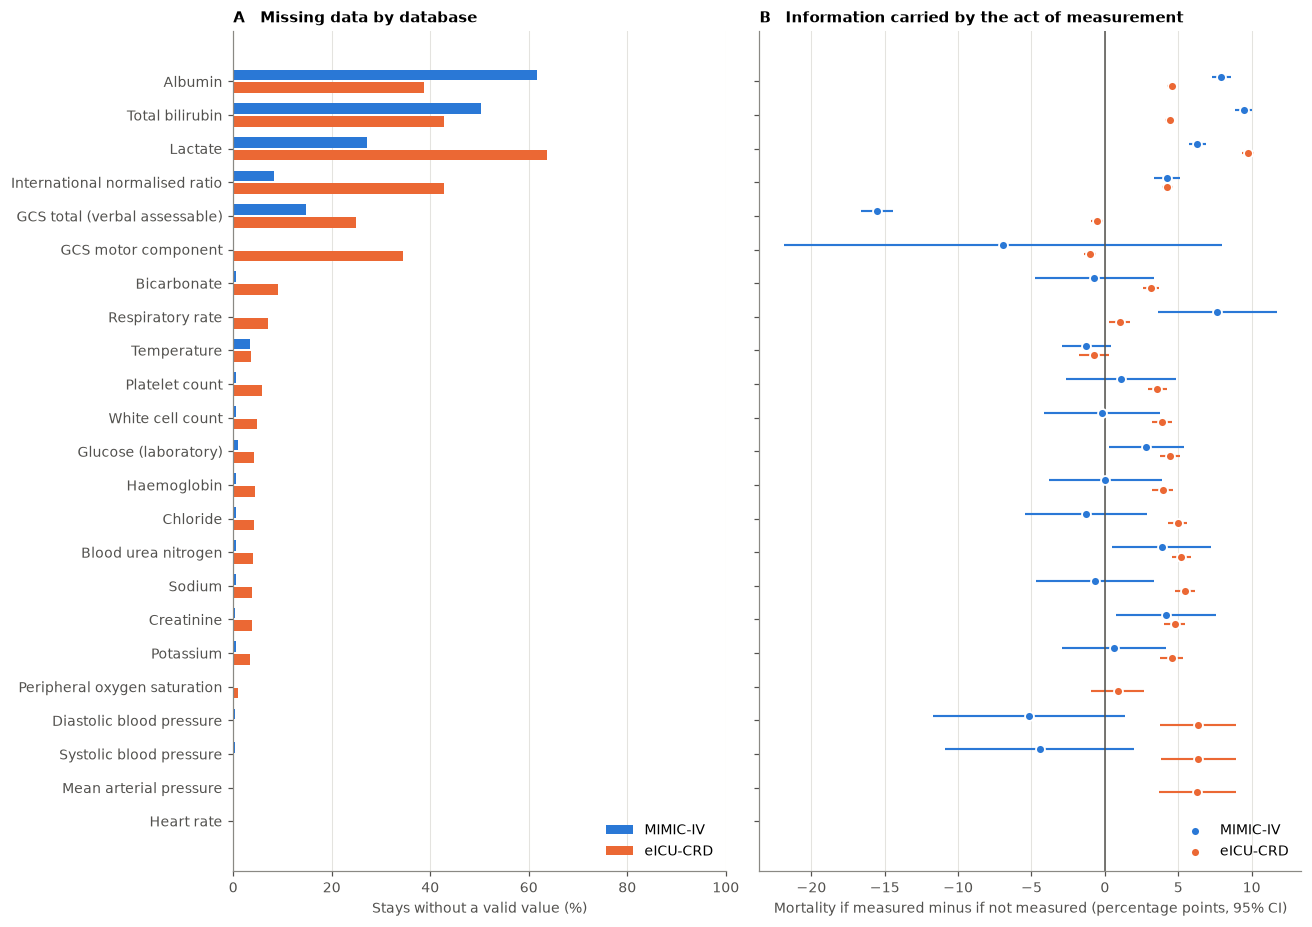

In [18]:
OUTCOME = "outcome_hospital_mortality"
first_agg = {r.variable: f"{r.variable}_{AGGREGATES[r.domain][0]}" for r in FEATURE_DICT.itertuples()}
rows = []
for var, col in first_agg.items():
    row = {"variable": var, "label": FEATURE_DICT.set_index("variable").loc[var, "label"]}
    for db, f in (("MIMIC-IV", mimic_main), ("eICU-CRD", eicu_main)):
        measured = f[col].notna()
        row[db] = 100 * (~measured).mean()
        if measured.sum() >= 20 and (~measured).sum() >= 20:
            m1, m0 = f.loc[measured, OUTCOME].mean(), f.loc[~measured, OUTCOME].mean()
            se = math.sqrt(m1 * (1 - m1) / measured.sum() + m0 * (1 - m0) / (~measured).sum())
            row[f"{db} diff"] = 100 * (m1 - m0)
            row[f"{db} diff lower"] = 100 * (m1 - m0 - 1.96 * se)
            row[f"{db} diff upper"] = 100 * (m1 - m0 + 1.96 * se)
        else:
            row[f"{db} diff"] = row[f"{db} diff lower"] = row[f"{db} diff upper"] = np.nan
    rows.append(row)
MISSING = pd.DataFrame(rows)
MISSING = MISSING.assign(_order=MISSING[["MIMIC-IV", "eICU-CRD"]].mean(axis=1)).sort_values(["_order", "label"]).drop(columns="_order").reset_index(drop=True)
save_table(MISSING.round(3), "tableS3_missingness",
           "Percentage of stays without a valid value and mortality difference measured minus not measured, by variable and database")

fig, axes = plt.subplots(1, 2, figsize=(12, 0.3 * len(MISSING) + 1.6), sharey=True, gridspec_kw={"width_ratios": [1, 1.1]})
y = np.arange(len(MISSING))
h = 0.38
ax = axes[0]
for offset, db in ((h / 2, "MIMIC-IV"), (-h / 2, "eICU-CRD")):
    ax.barh(y + offset, MISSING[db], height=h - 0.06, color=COLORS[db], label=db)
ax.set_yticks(y)
ax.set_yticklabels(MISSING["label"])
ax.set_xlim(0, 100)
ax.set_xlabel("Stays without a valid value (%)")
ax.set_title("Missing data by database")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
panel_label(ax, "A")

ax = axes[1]
for offset, db in ((0.14, "MIMIC-IV"), (-0.14, "eICU-CRD")):
    d = MISSING[f"{db} diff"]
    ok = d.notna()
    ax.hlines(y[ok] + offset, MISSING.loc[ok, f"{db} diff lower"], MISSING.loc[ok, f"{db} diff upper"], color=COLORS[db], linewidth=1.4)
    ax.scatter(d[ok], y[ok] + offset, s=34, color=COLORS[db], zorder=3, edgecolors="white", linewidths=1.2, label=db)
ax.axvline(0, color=INK2, linewidth=1)
ax.set_xlabel("Mortality if measured minus if not measured (percentage points, 95% CI)")
ax.set_title("Information carried by the act of measurement")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
panel_label(ax, "B")
fig.tight_layout()
save_figure(fig, "fig2_missingness", "Missing data by variable and database, and mortality difference between measured and unmeasured stays")

### 9.3 Recording frequency (Figure S2)

**Panel A.** Median number of valid raw measurements per stay in the window (the median number of hours with data is in Table S10). Vital signs are recorded far more densely in eICU-CRD.

**Panel B.** Standardised mean difference between databases for every vital-sign predictor under the two pre-specified hourly rules. Where the two rules give clearly different differences, part of the apparent case-mix difference is produced by the measurement process rather than by the patients. Notebook 3 repeats the external evaluation with the sensitivity rule to show whether this affects the transport of instability.

median_hours_with_data          median_valid_per_stay         
database                                     MIMIC-IV eICU-CRD              MIMIC-IV eICU-CRD
label                                                                                        
Albumin                                           NaN      NaN                   1.0      1.0
Bicarbonate                                       NaN      NaN                   2.0      2.0
Blood urea nitrogen                               NaN      NaN                   2.0      2.0
Chloride                                          NaN      NaN                   2.0      2.0
Creatinine                                        NaN      NaN                   2.0      2.0
Diastolic blood pressure                         23.0     24.0                  26.0     62.0
GCS motor component                               NaN      NaN                   6.0      5.0
GCS total (verbal assessable)                     NaN      NaN                   5.0      5.0
Glucose (laboratory)                              NaN      NaN                   2.0      2.0
Haemoglobin                                       NaN      NaN                   3.0      2.0
Heart rate                                       23.0     24.0                  26.0    284.0
International normalised ratio                    NaN      NaN                   2.0      1.0
Lactate                                           NaN      NaN                   3.0      2.0
Mean arterial pressure                           23.0     24.0                  26.0     62.0
Peripheral oxygen saturation                     23.0     24.0                  26.0    276.0
Platelet count                                    NaN      NaN                   3.0      2.0
Potassium                                         NaN      NaN                   2.0      2.0
Respiratory rate                                 23.0     24.0                  28.0    280.0
Sodium                                            NaN      NaN                   2.0      2.0
Systolic blood pressure                          23.0     24.0                  26.0     62.0
Temperature                                       7.0      6.0                   7.0      6.0
Total bilirubin                                   NaN      NaN                   1.0      1.0
White cell count                                  NaN      NaN                   2.0      2.0

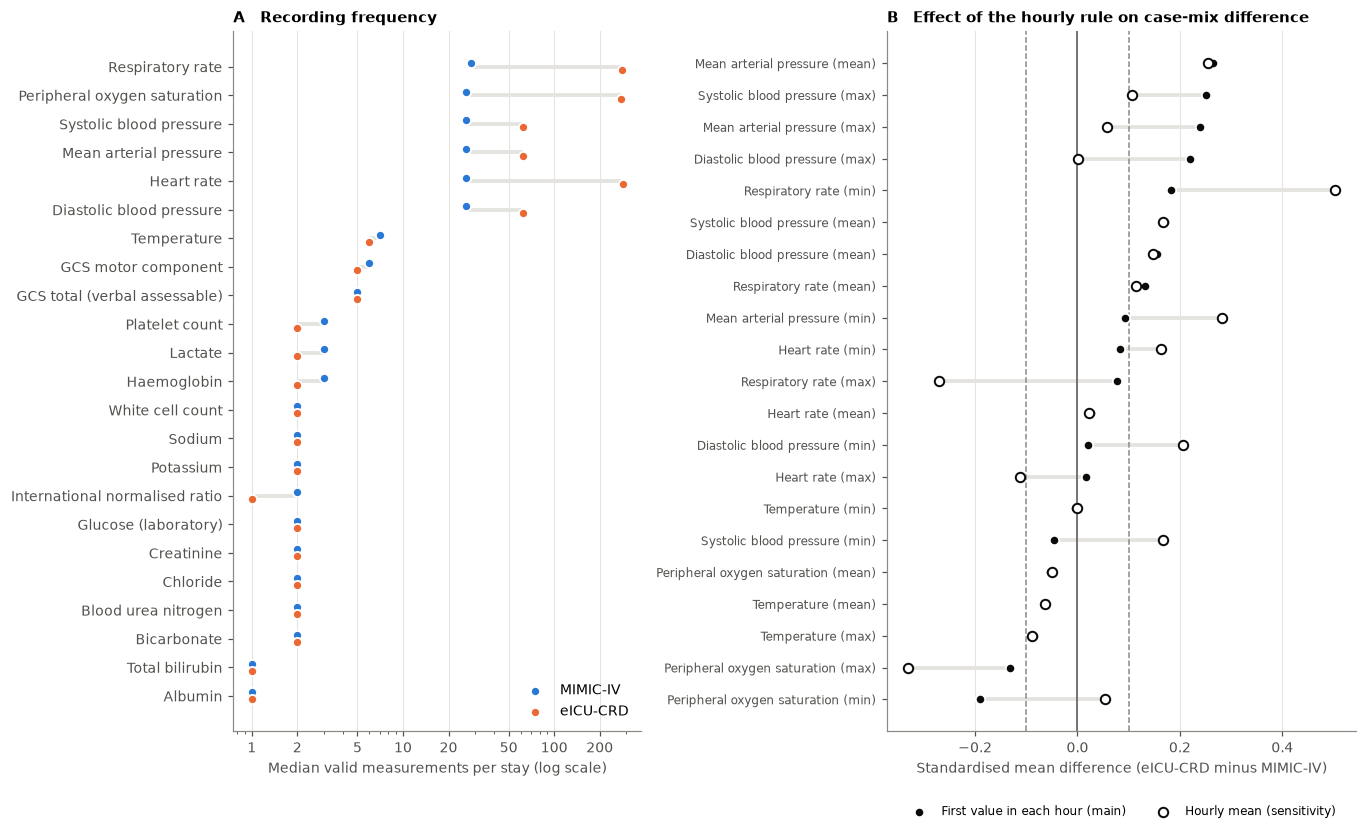

In [19]:
def density(long_frames, db, stays):
    long = pd.concat([f[[c for c in ("stay_id", "feature", "n_valid", "n_hours") if c in f]] for f in long_frames])
    long = long[long["stay_id"].isin(stays) & (long["n_valid"] > 0)]
    t = long.groupby("feature").agg(median_valid_per_stay=("n_valid", "median"),
                                    median_hours_with_data=("n_hours", "median")).reset_index()
    t["database"] = db
    return t


DENSITY = pd.concat([
    density([mimic_chart_long, mimic_lab_long], "MIMIC-IV", set(mimic_main["stay_id"])),
    density([eicu_vital_long, eicu_lab_long, eicu_gcs_long], "eICU-CRD", set(eicu_main["stay_id"])),
]).merge(FEATURE_DICT[["variable", "label", "domain"]], left_on="feature", right_on="variable").drop(columns="variable")
save_table(DENSITY, "tableS10_recording_frequency", "Median valid measurements per stay and hours with data, by variable and database")
display(DENSITY.pivot_table(index="label", columns="database", values=["median_valid_per_stay", "median_hours_with_data"]).round(1))

wide = DENSITY.pivot_table(index=["feature", "label", "domain"], columns="database", values="median_valid_per_stay").reset_index()
wide = wide.sort_values(["domain", "MIMIC-IV"]).reset_index(drop=True)
RULE_LABEL = {"first": "First value in each hour", "hmean": "Hourly mean"}
rule_rows = []
for main_col, alt_col in SENSITIVITY_VITALS.items():
    var, agg = main_col.rsplit("_", 1)
    rule_rows.append({"predictor": main_col, "label": f"{FEATURE_DICT.set_index('variable').loc[var, 'label']} ({agg})",
                      RULE_MAIN: smd_continuous(mimic_main[main_col], eicu_main[main_col]),
                      RULE_ALT: smd_continuous(mimic_main[alt_col], eicu_main[alt_col])})
RULE_SMD = pd.DataFrame(rule_rows)
RULE_SMD["change"] = (RULE_SMD["hmean"].abs() - RULE_SMD["first"].abs())
RULE_SMD = RULE_SMD.sort_values("first").reset_index(drop=True)
save_table(RULE_SMD.round(4), "tableS11_vital_rule_smd", "Between-database SMD of vital-sign predictors under the two hourly rules")

fig, axes = plt.subplots(1, 2, figsize=(12.5, max(0.27 * len(wide), 0.24 * len(RULE_SMD)) + 1.4), gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]
yy = np.arange(len(wide))
ax.hlines(yy, wide[["MIMIC-IV", "eICU-CRD"]].min(axis=1), wide[["MIMIC-IV", "eICU-CRD"]].max(axis=1), color=GRID, linewidth=2.5, zorder=1)
for offset, db in ((0.12, "MIMIC-IV"), (-0.12, "eICU-CRD")):
    ax.scatter(wide[db], yy + offset, s=36, color=COLORS[db], zorder=3, edgecolors="white", linewidths=1.2, label=db)
ax.set_xscale("log")
plain_log_axis(ax.xaxis)
ax.set_yticks(yy)
ax.set_yticklabels(wide["label"])
ax.set_xlabel("Median valid measurements per stay (log scale)")
ax.set_title("Recording frequency")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
panel_label(ax, "A")

ax = axes[1]
yy = np.arange(len(RULE_SMD))
ax.hlines(yy, RULE_SMD[["first", "hmean"]].min(axis=1), RULE_SMD[["first", "hmean"]].max(axis=1), color=GRID, linewidth=2.5, zorder=1)
ax.scatter(RULE_SMD["first"], yy, s=38, color=INK, zorder=3, edgecolors="white", linewidths=1.2,
           label=RULE_LABEL["first"] + (" (main)" if RULE_MAIN == "first" else " (sensitivity)"))
ax.scatter(RULE_SMD["hmean"], yy, s=38, facecolors="white", edgecolors=INK, linewidths=1.3, zorder=3,
           label=RULE_LABEL["hmean"] + (" (main)" if RULE_MAIN == "hmean" else " (sensitivity)"))
for ref in (-0.1, 0.1):
    ax.axvline(ref, color=NEUTRAL, linestyle="--", linewidth=1)
ax.axvline(0, color=INK2, linewidth=1)
ax.set_yticks(yy)
ax.set_yticklabels(RULE_SMD["label"], fontsize=8)
ax.set_xlabel("Standardised mean difference (eICU-CRD minus MIMIC-IV)")
ax.set_title("Effect of the hourly rule on case-mix difference")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2, fontsize=8)
panel_label(ax, "B")
fig.tight_layout()
save_figure(fig, "figS2_recording_frequency", "Recording frequency by database and effect of the hourly vital-sign rule on between-database SMD")

## 10. Table 1 and case-mix comparison

Continuous variables: median [interquartile range]; categorical: n (%). Standardised mean differences (SMD) compare eICU-CRD with MIMIC-IV; |SMD| above 0.1 is conventionally regarded as a meaningful imbalance.

In [20]:
def fmt_num(x):
    if pd.isna(x):
        return "NA"
    ax_ = abs(x)
    return f"{x:.0f}" if ax_ >= 100 else f"{x:.1f}" if ax_ >= 10 else f"{x:.2f}"


def describe_continuous(name, label, frames):
    row = {"characteristic": label}
    for db, f in frames.items():
        s = f[name]
        row[db] = f"{fmt_num(s.median())} [{fmt_num(s.quantile(0.25))}, {fmt_num(s.quantile(0.75))}]"
        row[f"{db} missing %"] = round(100 * s.isna().mean(), 1)
    dbs = list(frames)
    row["SMD"] = round(smd_continuous(frames[dbs[0]][name], frames[dbs[1]][name]), 3)
    return [row]


def describe_categorical(name, label, frames):
    rows = [{"characteristic": label}]
    levels = sorted(set().union(*[set(f[name].dropna().astype(str)) for f in frames.values()]))
    dbs = list(frames)
    for level in levels:
        row = {"characteristic": f"    {level}"}
        props = []
        for db, f in frames.items():
            s = f[name].astype("object")
            n = int((s.astype(str) == level).sum())
            p = n / len(f)
            props.append(p)
            row[db] = f"{n:,} ({100 * p:.1f})"
            row[f"{db} missing %"] = round(100 * s.isna().mean(), 1)
        row["SMD"] = round(smd_binary(*props), 3)
        rows.append(row)
    return rows


def describe_binary(name, label, frames):
    row = {"characteristic": label}
    props = []
    for db, f in frames.items():
        k = int((f[name] == 1).sum())
        props.append(k / len(f))
        row[db] = f"{k:,} ({100 * k / len(f):.1f})"
        row[f"{db} missing %"] = round(100 * f[name].isna().mean(), 1)
    row["SMD"] = round(smd_binary(*props), 3)
    return [row]


FRAMES = {"MIMIC-IV": mimic_main, "eICU-CRD": eicu_main}
table1 = [{"characteristic": "Stays, n", "MIMIC-IV": f"{len(mimic_main):,}", "eICU-CRD": f"{len(eicu_main):,}"},
          {"characteristic": "Hospitals, n", "MIMIC-IV": "1", "eICU-CRD": f"{eicu_main['site_id'].nunique():,}"}]
table1 += describe_continuous("age", "Age, years", FRAMES)
table1 += describe_categorical("sex", "Sex", FRAMES)
table1 += describe_categorical("race_group", "Race and ethnicity", FRAMES)
table1 += describe_categorical("care_unit_group", "ICU type", FRAMES)
table1 += describe_continuous("icu_los_hours", "ICU length of stay, h", FRAMES)
table1 += describe_binary("outcome_hospital_mortality", "In-hospital death after the landmark, n (%)", FRAMES)
table1 += describe_binary("outcome_icu_los_7d", "ICU stay of 7 days or more, n (%)", FRAMES)
KEY_PREDICTORS = ["heart_rate_max", "mbp_min", "resp_rate_max", "temperature_max", "spo2_min", "gcs_total_min",
                  "gcs_motor_min", "creatinine_max", "bun_max", "sodium_min", "potassium_max", "bicarbonate_min",
                  "glucose_max", "hemoglobin_min", "wbc_max", "platelets_min", "lactate_max", "bilirubin_max",
                  "albumin_min", "inr_max"]
units = FEATURE_DICT.set_index("variable")
for p in KEY_PREDICTORS:
    var, agg = p.rsplit("_", 1)
    table1 += describe_continuous(p, f"{units.loc[var, 'label']} ({agg}), {units.loc[var, 'unit']}", FRAMES)
TABLE1 = pd.DataFrame(table1)
save_table(TABLE1, "table1_characteristics", "Table 1: characteristics of the main cohorts by database")
display(TABLE1)

full = []
for p in PREDICTORS:
    if p == "sex_male":
        full += describe_categorical("sex", "Sex", FRAMES)
    elif p == "age":
        full += describe_continuous("age", "Age, years", FRAMES)
    else:
        var, agg = p.rsplit("_", 1)
        full += describe_continuous(p, f"{units.loc[var, 'label']} ({agg})", FRAMES)
TABLE_S4 = pd.DataFrame(full)
save_table(TABLE_S4, "tableS4_all_predictors_by_database", "All candidate predictors by database with SMD")

by_outcome = []
for db, f in FRAMES.items():
    groups = {"Survived": f[f["outcome_hospital_mortality"] == 0], "Died": f[f["outcome_hospital_mortality"] == 1]}
    for p in ["age"] + KEY_PREDICTORS:
        r = describe_continuous(p, p, groups)[0]
        r["database"] = db
        by_outcome.append(r)
TABLE_S5 = pd.DataFrame(by_outcome)
save_table(TABLE_S5, "tableS5_predictors_by_outcome", "Key predictors by in-hospital outcome within each database")

,characteristic,MIMIC-IV,eICU-CRD,MIMIC-IV missing %,eICU-CRD missing %,SMD
0,"Stays, n","39,966","94,114",NaN,NaN,NaN
1,"Hospitals, n",1,205,NaN,NaN,NaN
2,"Age, years","67.0 [55.0, 78.0]","66.0 [54.0, 77.0]",0.0,0.0,-0.052
3,Sex,NaN,NaN,NaN,NaN,NaN
4,F,"17,341 (43.4)","42,921 (45.6)",0.0,0.0,0.045
5,M,"22,625 (56.6)","51,174 (54.4)",0.0,0.0,-0.045
6,Race and ethnicity,NaN,NaN,NaN,NaN,NaN
7,Asian,"1,155 (2.9)","1,633 (1.7)",0.0,0.0,-0.077
8,Black,"3,470 (8.7)","10,040 (10.7)",0.0,0.0,0.067
9,Hispanic,"1,386 (3.5)","3,518 (3.7)",0.0,0.0,0.014


WindowsPath('C:/Users/kruta/Downloads/outputs/part1/tables/tableS5_predictors_by_outcome.csv')

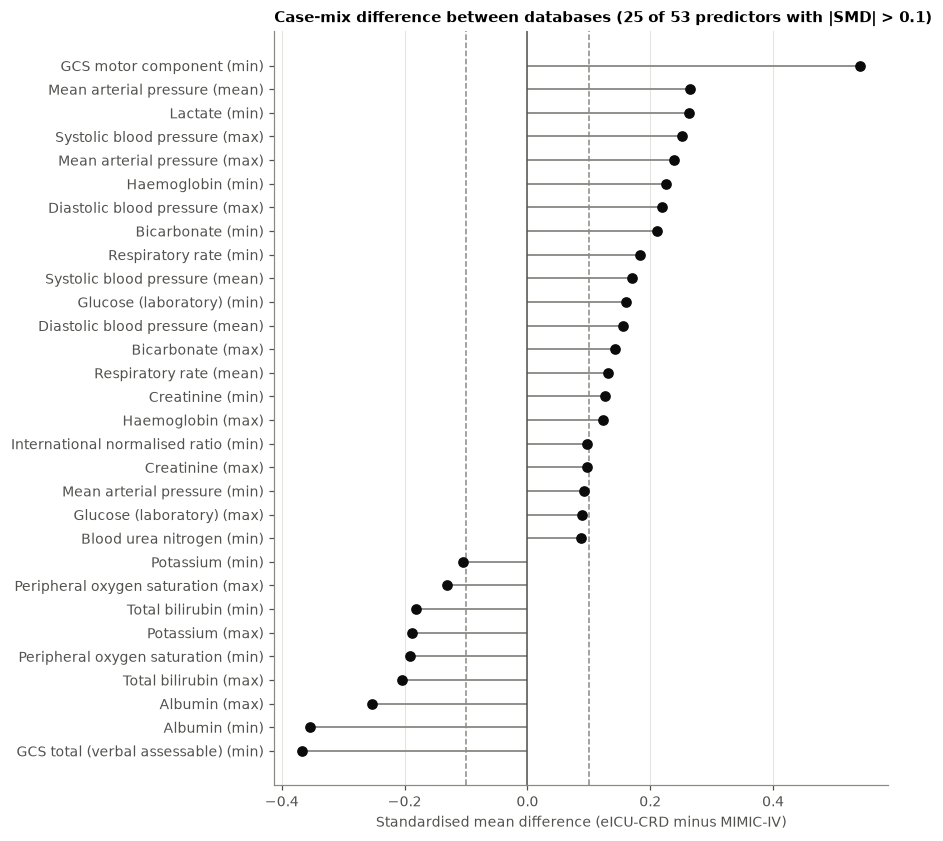

In [21]:
SMD = pd.DataFrame({
    "predictor": PREDICTORS,
    "smd": [smd_continuous(mimic_main[p], eicu_main[p]) for p in PREDICTORS],
})
SMD["abs_smd"] = SMD["smd"].abs()
pretty = {}
for p in PREDICTORS:
    if p in ("age", "sex_male"):
        pretty[p] = {"age": "Age", "sex_male": "Male sex"}[p]
    else:
        var, agg = p.rsplit("_", 1)
        pretty[p] = f"{units.loc[var, 'label']} ({agg})"
SMD["label"] = SMD["predictor"].map(pretty)
save_table(SMD.sort_values("abs_smd", ascending=False), "tableS6_case_mix_smd", "Standardised mean differences, eICU-CRD vs MIMIC-IV, all predictors")

top = SMD.sort_values("abs_smd", ascending=False).head(30).sort_values("smd")
fig, ax = plt.subplots(figsize=(7.2, 0.25 * len(top) + 1.4))
yy = np.arange(len(top))
ax.hlines(yy, 0, top["smd"], color=NEUTRAL, linewidth=1.2)
ax.scatter(top["smd"], yy, s=36, color=INK, zorder=3)
for ref in (-0.1, 0.1):
    ax.axvline(ref, color=NEUTRAL, linestyle="--", linewidth=1)
ax.axvline(0, color=INK2, linewidth=1)
ax.set_yticks(yy)
ax.set_yticklabels(top["label"])
ax.set_xlabel("Standardised mean difference (eICU-CRD minus MIMIC-IV)")
n_imbalanced = int((SMD["abs_smd"] > 0.1).sum())
ax.set_title(f"Case-mix difference between databases ({n_imbalanced} of {len(SMD)} predictors with |SMD| > 0.1)")
ax.grid(axis="y", visible=False)
save_figure(fig, "fig3_case_mix_smd", "Standardised mean differences between eICU-CRD and MIMIC-IV, 30 largest")

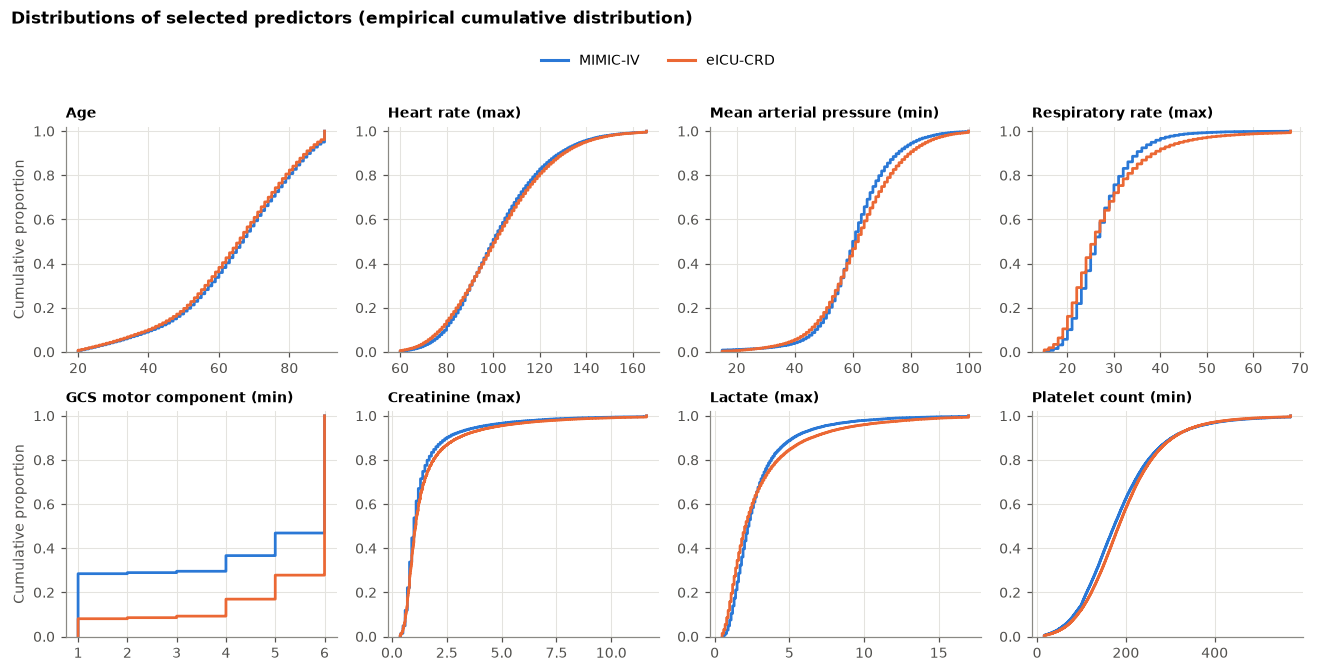

In [22]:
ECDF_VARS = ["age", "heart_rate_max", "mbp_min", "resp_rate_max", "gcs_motor_min", "creatinine_max", "lactate_max", "platelets_min"]
fig, axes = plt.subplots(2, 4, figsize=(12, 5.6))
for ax, var in zip(axes.ravel(), ECDF_VARS):
    pooled = pd.concat([mimic_main[var], eicu_main[var]]).dropna()
    lo, hi = pooled.quantile([0.005, 0.995]) if len(pooled) else (0, 1)
    for db, f in FRAMES.items():
        v = np.sort(f[var].dropna().clip(lo, hi).to_numpy())
        if len(v):
            ax.step(v, np.arange(1, len(v) + 1) / len(v), where="post", color=COLORS[db], linewidth=1.8, label=db)
    ax.set_title(pretty[var], fontsize=9)
    ax.set_ylim(0, 1.02)
    ax.set_ylabel("Cumulative proportion" if ax in axes[:, 0] else "")
handles = [Line2D([0], [0], color=COLORS[d], lw=2) for d in FRAMES]
fig.legend(handles, list(FRAMES), loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.03))
fig.suptitle("Distributions of selected predictors (empirical cumulative distribution)", x=0.01, ha="left", y=1.08, fontweight="bold")
fig.tight_layout()
save_figure(fig, "fig4_predictor_distributions", "Empirical cumulative distributions of eight key predictors by database")

## 11. eICU-CRD hospital landscape (Figure 5)

Hospital-level analyses in notebook 3 need hospitals with enough patients and events. The funnel plot shows each hospital's crude in-hospital mortality against its number of eligible first stays with 95% and 99.8% binomial control limits around the pooled rate. Hospitals at or above the pre-specified minimum size are filled.

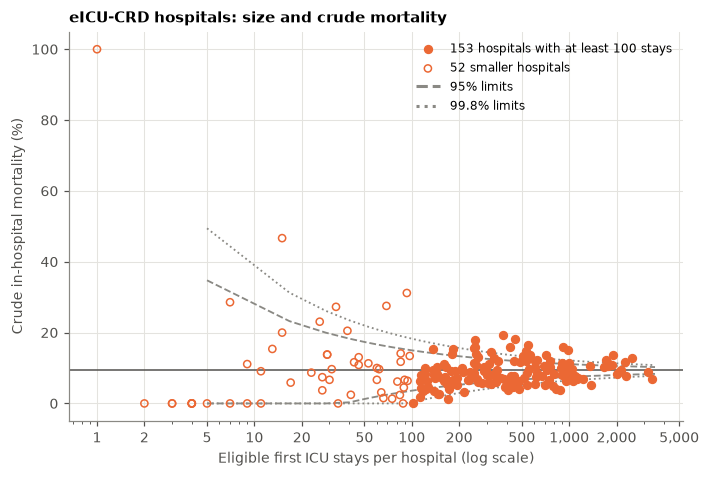

Hospitals: 205; with >= 100 stays: 153 covering 92,071 stays


In [23]:
hosp = (eicu_main.groupby("site_id")
        .agg(stays=("stay_id", "size"), deaths=("outcome_hospital_mortality", "sum"),
             region=("hospital_region", "first"), teaching=("hospital_teaching", "first"), beds=("hospital_beds", "first"))
        .reset_index())
hosp["mortality"] = hosp["deaths"] / hosp["stays"]
p0 = eicu_main["outcome_hospital_mortality"].mean()
min_n = CONFIG["min_hospital_stays"]
big = hosp["stays"] >= min_n
save_table(hosp.sort_values("stays", ascending=False), "tableS7_eicu_hospitals", "eICU-CRD hospitals: eligible first stays, deaths and characteristics")

fig, ax = plt.subplots(figsize=(7.2, 4.6))
n_grid = np.linspace(max(5, hosp["stays"].min()), hosp["stays"].max() * 1.05, 300)
for z, style in ((1.96, "--"), (3.09, ":")):
    half = z * np.sqrt(p0 * (1 - p0) / n_grid)
    ax.plot(n_grid, 100 * np.clip(p0 + half, 0, 1), color=NEUTRAL, linestyle=style, linewidth=1.2)
    ax.plot(n_grid, 100 * np.clip(p0 - half, 0, 1), color=NEUTRAL, linestyle=style, linewidth=1.2)
ax.axhline(100 * p0, color=INK2, linewidth=1)
ax.scatter(hosp.loc[big, "stays"], 100 * hosp.loc[big, "mortality"], s=26, color=COLORS["eICU-CRD"], zorder=3,
           label=f"{int(big.sum())} hospitals with at least {min_n} stays")
ax.scatter(hosp.loc[~big, "stays"], 100 * hosp.loc[~big, "mortality"], s=22, facecolors="none",
           edgecolors=COLORS["eICU-CRD"], linewidths=1, zorder=3, label=f"{int((~big).sum())} smaller hospitals")
ax.set_xscale("log")
plain_log_axis(ax.xaxis)
ax.set_xlabel("Eligible first ICU stays per hospital (log scale)")
ax.set_ylabel("Crude in-hospital mortality (%)")
ax.set_title("eICU-CRD hospitals: size and crude mortality")
ax.legend(handles=ax.get_legend_handles_labels()[0] + [Line2D([0], [0], color=NEUTRAL, ls="--"), Line2D([0], [0], color=NEUTRAL, ls=":")],
          labels=ax.get_legend_handles_labels()[1] + ["95% limits", "99.8% limits"], loc="upper right", fontsize=8)
save_figure(fig, "fig5_eicu_hospital_funnel", "Funnel plot of crude in-hospital mortality by eICU-CRD hospital size")
print(f"Hospitals: {len(hosp)}; with >= {min_n} stays: {int(big.sum())} covering {int(hosp.loc[big, 'stays'].sum()):,} stays")

## 12. Sample-size context (Figure 6)

Two quantities frame the instability analyses in notebook 2.

**Panel A.** Minimum development sample size from the three analytic criteria for binary outcomes (shrinkage of at least 0.9, small optimism in R-squared, precise overall risk) for the observed MIMIC-IV mortality, across anticipated C statistics. It is shown for the core predictors and for the full candidate set including missingness indicators (one indicator for each source variable with any missing values).

**Panel B.** Expected heuristic shrinkage (van Houwelingen and le Cessie), `S = 1 - P / LR` with the anticipated likelihood-ratio statistic `LR = -n ln(1 - R2_CS)`, across development sizes, with the sizes evaluated in notebook 2 marked. Values well below 0.9 indicate overfitting and anticipate unstable individual predictions; the instability audit in notebook 2 measures directly what this heuristic only anticipates.

MIMIC-IV main cohort: n = 39,966, mortality = 9.728%; candidate parameters: core 53, with indicators 75


,anticipated_c,parameters,set,r2_cox_snell,minimum_n,minimum_events,criterion_1,criterion_2,criterion_3
0,0.70,53,core predictors,0.0465,9995,972.3,9995,2168,135
1,0.70,75,with missingness indicators,0.0465,14144,1376.0,14144,3068,135
2,0.75,53,core predictors,0.0742,6164,599.7,6164,2136,135
3,0.75,75,with missingness indicators,0.0742,8723,848.6,8723,3022,135
4,0.80,53,core predictors,0.1098,4073,396.2,4073,2094,135
5,0.80,75,with missingness indicators,0.1098,5763,560.6,5763,2963,135
6,0.85,53,core predictors,0.1552,2801,272.5,2801,2040,135
7,0.85,75,with missingness indicators,0.1552,3964,385.6,3964,2887,135
8,0.90,53,core predictors,0.2133,1969,191.5,1960,1969,135
9,0.90,75,with missingness indicators,0.2133,2787,271.1,2774,2787,135


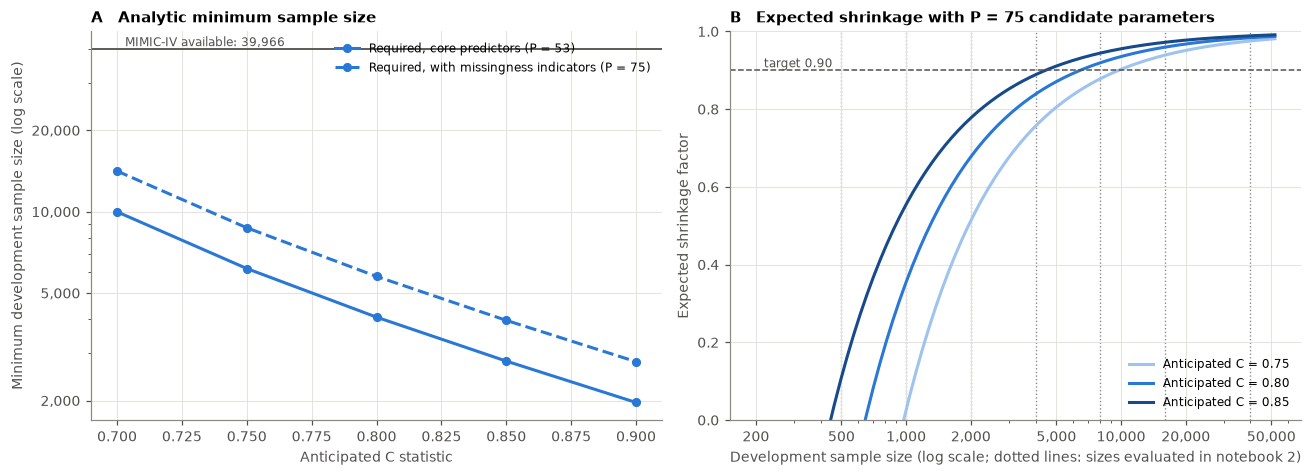

In [24]:
prev = mimic_main["outcome_hospital_mortality"].mean()
n_dev = len(mimic_main)
P_core = len(PREDICTORS)
P_full = P_core + int(sum(mimic_main[cols].isna().any().any() for cols in MISSING_GROUPS.values()))
print(f"MIMIC-IV main cohort: n = {n_dev:,}, mortality = {prev:.3%}; candidate parameters: core {P_core}, with indicators {P_full}")

ss_rows = []
r2_by_c = {}
for c in CONFIG["anticipated_c_grid"]:
    r2 = cox_snell_r2_from_c(c, prev, n_sim=400_000, random_state=CONFIG["seed"])
    r2_by_c[c] = r2
    for label, P in (("core predictors", P_core), ("with missingness indicators", P_full)):
        res = minimum_sample_size_binary(P, prev, r2_cox_snell=r2)
        crit = res.criteria.set_index("criterion")["sample_size"]
        ss_rows.append({"anticipated_c": c, "parameters": P, "set": label, "r2_cox_snell": round(r2, 4),
                        "minimum_n": res.minimum_n, "minimum_events": round(res.minimum_events, 1),
                        "criterion_1": int(crit.iloc[0]), "criterion_2": int(crit.iloc[1]), "criterion_3": int(crit.iloc[2])})
SAMPLE_SIZE = pd.DataFrame(ss_rows)
save_table(SAMPLE_SIZE, "tableS8_minimum_sample_size", "Analytic minimum sample size by anticipated C statistic and candidate parameter count")
display(SAMPLE_SIZE)

design = [s for s in CONFIG["design_sizes"] if s < n_dev] + [n_dev]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]
for label, style in (("core predictors", "-"), ("with missingness indicators", "--")):
    sub = SAMPLE_SIZE[SAMPLE_SIZE["set"] == label]
    ax.plot(sub["anticipated_c"], sub["minimum_n"], style, color=COLORS["MIMIC-IV"], marker="o", markersize=5,
            label=f"Required, {label} (P = {sub['parameters'].iloc[0]})")
ax.axhline(n_dev, color=INK2, linewidth=1.2)
ax.text(CONFIG["anticipated_c_grid"][0], n_dev, f"  MIMIC-IV available: {n_dev:,}", va="bottom", fontsize=8, color=INK2)
ax.set_yscale("log")
plain_log_axis(ax.yaxis)
ax.set_xlabel("Anticipated C statistic")
ax.set_ylabel("Minimum development sample size (log scale)")
ax.set_title("Analytic minimum sample size")
ax.legend(fontsize=8, loc="upper right")
panel_label(ax, "A")

ax = axes[1]
n_grid = np.unique(np.geomspace(200, max(n_dev, max(CONFIG["design_sizes"])) * 1.3, 160).astype(int))
shades = {0.75: "#9fc3ef", 0.80: COLORS["MIMIC-IV"], 0.85: "#174a8b"}
for c, colour in shades.items():
    r2 = r2_by_c.get(c) or cox_snell_r2_from_c(c, prev, n_sim=400_000, random_state=CONFIG["seed"])
    shrink = 1 - P_full / (-n_grid * np.log(1 - r2))
    ax.plot(n_grid, shrink, color=colour, label=f"Anticipated C = {c:.2f}")
ax.axhline(0.9, color=INK2, linestyle="--", linewidth=1)
ax.text(n_grid[0], 0.9, "  target 0.90", va="bottom", fontsize=8, color=INK2)
for s in design:
    ax.axvline(s, color=NEUTRAL, linewidth=0.9, linestyle=":", zorder=0)
ax.set_xscale("log")
plain_log_axis(ax.xaxis)
ax.set_ylim(0, 1.0)
ax.set_xlabel("Development sample size (log scale; dotted lines: sizes evaluated in notebook 2)")
ax.set_ylabel("Expected shrinkage factor")
ax.set_title(f"Expected shrinkage with P = {P_full} candidate parameters")
ax.legend(fontsize=8, loc="lower right")
panel_label(ax, "B")
fig.tight_layout()
save_figure(fig, "fig6_sample_size_context", "Analytic minimum sample size and expected shrinkage across development sizes")

## 13. Calendar-period context (Figure S1)

Crude mortality by MIMIC-IV anchor-year group and eICU-CRD discharge year with Wilson 95% intervals. Notebook 3 uses this when interpreting differences between development and external populations.

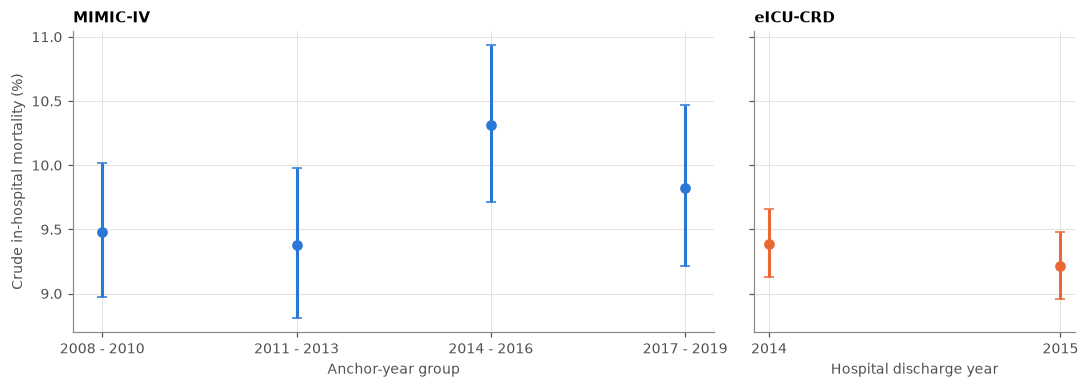

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True, gridspec_kw={"width_ratios": [2, 1]})
period_rows = []
for ax, (db, f) in zip(axes, FRAMES.items()):
    g = f.groupby("year_group")["outcome_hospital_mortality"].agg(["sum", "size"]).reset_index().sort_values("year_group")
    lo_hi = [wilson(k, n) for k, n in zip(g["sum"], g["size"])]
    g["mortality"] = g["sum"] / g["size"]
    g["lower"], g["upper"] = [x[0] for x in lo_hi], [x[1] for x in lo_hi]
    x = np.arange(len(g))
    ax.errorbar(x, 100 * g["mortality"], yerr=[100 * (g["mortality"] - g["lower"]), 100 * (g["upper"] - g["mortality"])],
                fmt="o", color=COLORS[db], capsize=3, markersize=6)
    ax.set_xticks(x)
    ax.set_xticklabels(g["year_group"], rotation=0)
    ax.set_title(db)
    ax.set_xlabel("Anchor-year group" if db == "MIMIC-IV" else "Hospital discharge year")
    period_rows.append(g.assign(database=db))
axes[0].set_ylabel("Crude in-hospital mortality (%)")
fig.tight_layout()
save_table(pd.concat(period_rows), "tableS9_mortality_by_period", "Crude mortality by calendar period")
save_figure(fig, "figS1_mortality_by_period", "Crude in-hospital mortality by calendar period and database")

## 14. Study flow diagram (Figure 1)

Drawn last so that it reflects the final exclusion step.

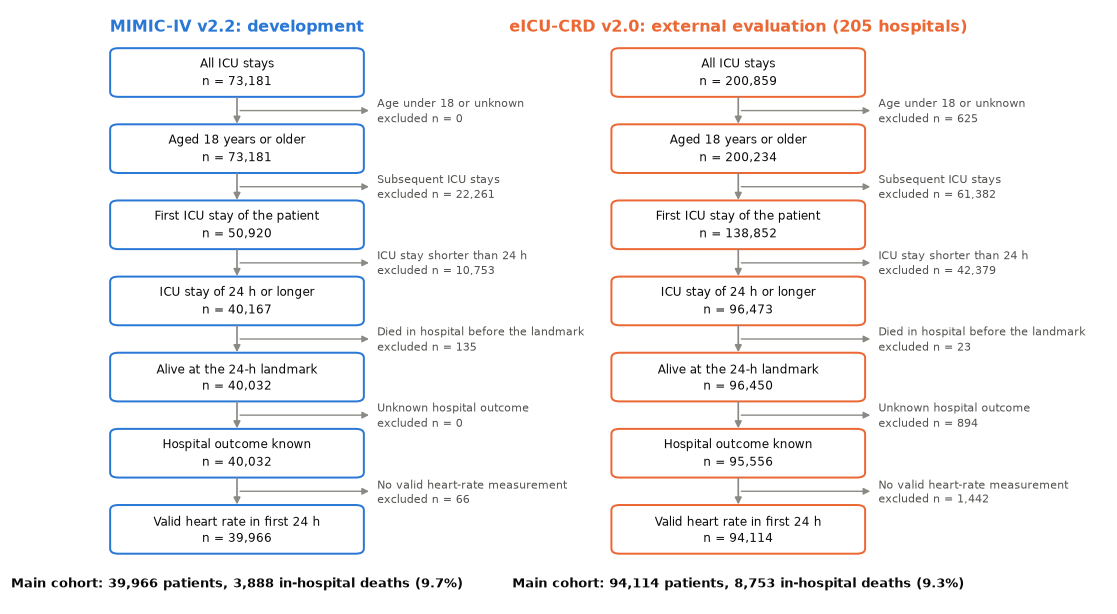

In [26]:
def draw_flow(ax, flow, x, colour, title):
    box_w, box_h, gap = 0.24, 0.07, 0.122
    y = 0.90
    ax.text(x, 0.985, title, ha="center", va="top", fontsize=10.5, fontweight="bold", color=colour)
    for i, row in enumerate(flow.itertuples()):
        text = f"{row.step}\nn = {row.remaining:,}"
        ax.add_patch(FancyBboxPatch((x - box_w / 2, y - box_h / 2), box_w, box_h,
                                    boxstyle="round,pad=0.004,rounding_size=0.008",
                                    linewidth=1.3, edgecolor=colour, facecolor="white"))
        ax.text(x, y, text, ha="center", va="center", fontsize=8, color=INK, linespacing=1.4)
        if i < len(flow) - 1:
            nxt = flow.iloc[i + 1]
            ax.annotate("", xy=(x, y - gap + box_h / 2), xytext=(x, y - box_h / 2),
                        arrowprops=dict(arrowstyle="-|>", color=NEUTRAL, lw=1.1))
            ym = y - gap / 2
            ax.annotate("", xy=(x + box_w / 2 + 0.012, ym), xytext=(x, ym),
                        arrowprops=dict(arrowstyle="-|>", color=NEUTRAL, lw=0.9))
            ax.text(x + box_w / 2 + 0.017, ym, f"{nxt['exclusion']}\nexcluded n = {int(nxt['excluded']):,}",
                    ha="left", va="center", fontsize=7.2, color=INK2, linespacing=1.3)
        y -= gap


fig, ax = plt.subplots(figsize=(12, 7.0))
ax.set_axis_off()
ax.set_xlim(0, 1)
ax.set_ylim(0.05, 1)
draw_flow(ax, m_flow, 0.15, COLORS["MIMIC-IV"], "MIMIC-IV v2.2: development")
draw_flow(ax, e_flow, 0.64, COLORS["eICU-CRD"], f"eICU-CRD v2.0: external evaluation ({eicu_main['site_id'].nunique()} hospitals)")
for x, f, db in ((0.15, mimic_main, "MIMIC-IV"), (0.64, eicu_main, "eICU-CRD")):
    ax.text(x, 0.075, f"Main cohort: {len(f):,} patients, {int(f.outcome_hospital_mortality.sum()):,} in-hospital deaths "
            f"({100 * f.outcome_hospital_mortality.mean():.1f}%)", ha="center", fontsize=8.5, fontweight="bold", color=INK)
save_figure(fig, "fig1_study_flow", "Study flow for MIMIC-IV and eICU-CRD")

## 15. Study summary and provenance

The summary below is read by notebooks 2 and 3 and provides the numbers quoted in the Methods and Results.

In [27]:
def cohort_numbers(f):
    return {"stays": int(len(f)), "patients": int(f["patient_id"].nunique()), "sites": int(f["site_id"].nunique()),
            "deaths": int(f["outcome_hospital_mortality"].sum()), "mortality": float(f["outcome_hospital_mortality"].mean()),
            "icu_los_7d_events": int(f["outcome_icu_los_7d"].sum()), "icu_los_7d_rate": float(f["outcome_icu_los_7d"].mean())}


SUMMARY = {
    "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
    "cohorts": {"mimic_main": cohort_numbers(mimic_main), "mimic_all_stays": cohort_numbers(mimic_all),
                "eicu_main": cohort_numbers(eicu_main), "eicu_all_stays": cohort_numbers(eicu_all)},
    "eicu_hospitals_total": int(len(hosp)),
    "eicu_hospitals_min_size": int(big.sum()),
    "min_hospital_stays": CONFIG["min_hospital_stays"],
    "n_predictors": len(PREDICTORS),
    "candidate_parameters_core": P_core,
    "candidate_parameters_with_indicators": P_full,
    "minimum_sample_size_at_c080": SAMPLE_SIZE.query("anticipated_c == 0.8").set_index("set")["minimum_n"].to_dict(),
    "design_sizes_for_notebook2": design,
    "predictors_with_abs_smd_gt_0.1": int((SMD["abs_smd"] > 0.1).sum()),
    "source_tables": SOURCES[["database", "table", "format", "path"]].to_dict(orient="records"),
}
save_json(SUMMARY, "study_summary", "Key cohort numbers and planning values for notebooks 2 and 3", folder="data")
display(pd.json_normalize(SUMMARY["cohorts"], sep=" / ").T.rename(columns={0: "value"}))

manifest_path = PROV.save({"config": {k: (str(v) if isinstance(v, Path) else v) for k, v in CONFIG.items()}})
print("Provenance manifest:", manifest_path)
print("Final chain hash:   ", PROV.chain)
display(pd.DataFrame(PROV.steps))
con.close()

,value
mimic_main / stays,39966.000000
mimic_main / patients,39966.000000
mimic_main / sites,1.000000
mimic_main / deaths,3888.000000
mimic_main / mortality,0.097283
mimic_main / icu_los_7d_events,5228.000000
mimic_main / icu_los_7d_rate,0.130811
mimic_all_stays / stays,57464.000000
mimic_all_stays / patients,42071.000000
mimic_all_stays / sites,1.000000


Provenance manifest: C:\Users\kruta\Downloads\outputs\part1\logs\provenance_manifest.json
Final chain hash:    badcfe0bb3e5915d9a0594ba2d55b63af121e980df457a7ff96f391076ba5d99


,step,seconds
0,MIMIC-IV cohort,0.6
1,eICU-CRD cohort,2.2
2,"MIMIC-IV chartevents (vital signs, GCS)",13.7
3,MIMIC-IV labevents,3.9
4,eICU-CRD vitalPeriodic + vitalAperiodic + nurseCharting temperature,53.7
5,eICU-CRD lab,3.0
6,eICU-CRD nurseCharting (GCS),0.4
7,Assemble datasets,16.6


## 16. Reporting checklist coverage (TRIPOD+AI)

| TRIPOD+AI item | Where addressed in this notebook |
|---|---|
| 5a, 5b: data sources, dates | Sections 3, 6 (release integrity), 13; Tables S0 and S9 |
| 6a, 6b: setting, eligibility | Sections 1, 5, 6; Figure 1; flow counts |
| 7: data preparation | Sections 4, 7, 9; Tables S1 and S2 |
| 8a: outcome definition and timing | Sections 1, 5, 6 |
| 9a, 9b: predictors, definitions and timing | Section 4; Table S1 |
| 10: sample size | Section 12; Figure 6; Table S8 |
| 11: missing data | Section 9.2; Figure 2; Table S3 (handling inside pipelines: notebook 2) |
| 7: data quality, recording frequency | Sections 9.1 and 9.3; Tables S2 and S10; Figure S2 |
| 20a: participant flow | Figure 1 |
| 20b: participant characteristics, comparison of development and evaluation data | Table 1, Tables S4 and S5, Figures 3 and 4 |

## 17. Checks before moving to notebook 2

1. **Release integrity** (Table S0): every row should show `matches = True`. If not, the local copy is incomplete or a different version.
2. **Item verification** (Section 4): passed, otherwise the notebook would have stopped.
3. **Implausible values** (Table S2): removal rates are normally well below 1%. A variable with several per cent removed suggests a unit or mapping problem.
4. **Missingness** (Figure 2A): heart rate, blood pressure, respiratory rate and SpO2 should be almost complete in both databases; lactate, albumin, bilirubin and INR are expected to be missing for a substantial share of stays.
5. **Flow and outcome rates** (Figure 1): in-hospital mortality after the 24-h landmark is typically in the high single digits to low teens in both databases.
6. **Hourly rule** (Figure S2B): note which vital-sign predictors change their between-database difference markedly under the sensitivity rule; these are revisited in notebook 3.

**Next: notebook 2** reads `outputs/part1/data/analysis_spec.json` and the MIMIC-IV datasets, fits each model class, and runs the bootstrap instability audit with `cpmaudit`.